In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import sklearn
import lightgbm
import xgboost
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline

In [2]:
sales_df = pd.read_csv( "../Data/OG Data/ecommerce_sales_customer_analytics_150k.csv")
print("Sales Data Loaded Successfully")
print("Rows:", sales_df.shape[0])
print("Columns:", sales_df.shape[1])

sales_df.head()

Sales Data Loaded Successfully
Rows: 138116
Columns: 46


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8


In [3]:
customer_df = pd.read_csv("../Data/OG Data/customer_master.csv")
print("Customers Data Loaded Successfully")
print("Rows:", customer_df.shape[0])
print("Columns:", customer_df.shape[1])

customer_df.head()

Customers Data Loaded Successfully
Rows: 25000
Columns: 11


,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34


In [4]:
order_items_df = pd.read_csv("../Data/OG Data/order_items.csv")

print("Order Items Data Loaded Successfully")
print("Rows:", order_items_df.shape[0])
print("Columns:", order_items_df.shape[1])

order_items_df.head()

Order Items Data Loaded Successfully
Rows: 397569
Columns: 12


,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53


In [5]:
product_df = pd.read_csv("../Data/OG Data/product_catalog.csv")

print("Product Data Loaded Successfully")
print("Rows:", product_df.shape[0])
print("Columns:", product_df.shape[1])

product_df.head()

Product Data Loaded Successfully
Rows: 1175
Columns: 9


,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,1120.49,564.86,4.8
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,1282.18,695.54,2.9


In [6]:
statistics_df = pd.read_csv("../Data/OG Data/dataset_statistics.csv")

print("Dataset Statistics Loaded Successfully")
print("Rows:", statistics_df.shape[0])
print("Columns:", statistics_df.shape[1])

statistics_df.head()

Dataset Statistics Loaded Successfully
Rows: 1
Columns: 11


,Total Transactions,Total Columns,Total Customers,Total Products Used,Date Range,Total Revenue,Total Profit,Average Order Value,Average Rating,Return Rate,Cancellation Rate
0,138116,46,24911,138116,2021-01-01 to 2025-12-31,"$177,134,263.74","$76,146,395.76","$1,282.50",3.68,6.85%,6.08%


In [7]:
datasets = {
    "Sales": sales_df,
    "Customers": customer_df,
    "Order Items": order_items_df,
    "Products": product_df,
    "Dataset Statistics": statistics_df
}

for name, df in datasets.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    print("Shape:")
    print(df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nInfo:")
    df.info()

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\n" + "=" * 70)
    print()

Sales
Shape:
(138116, 46)

Columns:
['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'profit', 'profit_margin_percentage', 'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count']

Info:
<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Co

In [8]:
# Convert order_date to datetim
sales_df["order_date"] = pd.to_datetime(sales_df["order_date"],)

In [9]:
# Convert order_time to string
sales_df["order_time"] = sales_df["order_time"].astype("string")

In [10]:
# Convert text / categorical columns to string
string_columns = [
    "order_id",
    "order_status",
    "sales_channel",
    "customer_id",
    "customer_name",
    "gender",
    "customer_segment",
    "customer_type",
    "customer_city",
    "customer_state",
    "customer_country",
    "region",
    "payment_method",
    "payment_status",
    "currency",
    "shipping_method",
    "warehouse",
    "delivery_status",
    "return_status",
    "return_reason",
    "review_sentiment",
    "customer_review",
    "marketing_channel",
    "campaign_name",
    "coupon_code"
]

for col in string_columns:
    sales_df[col] = sales_df[col].astype("string")

In [11]:
# Convert integer columns
integer_columns = [
    "customer_age",
    "customer_postal_code",
    "loyalty_points_earned",
    "loyalty_points_redeemed",
    "quantity",
    "customer_order_count"
]
for col in integer_columns:
    sales_df[col] = pd.to_numeric(sales_df[col]).astype("Int64")

In [12]:
# Convert decimal / numeric columns
float_columns = [
    "delivery_days",
    "estimated_delivery_days",
    "customer_rating",
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "profit",
    "profit_margin_percentage",
    "customer_lifetime_value"
]

for col in float_columns:
    sales_df[col] = pd.to_numeric(sales_df[col])

In [13]:
# Ensure boolean column
sales_df["is_repeat_customer"] = sales_df["is_repeat_customer"].astype("boolean")

In [14]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   order_id                  138116 non-null  string        
 1   order_date                138116 non-null  datetime64[us]
 2   order_time                138116 non-null  string        
 3   order_status              138116 non-null  string        
 4   sales_channel             138116 non-null  string        
 5   customer_id               138116 non-null  string        
 6   customer_name             138116 non-null  string        
 7   customer_age              138116 non-null  Int64         
 8   gender                    138116 non-null  string        
 9   customer_segment          138116 non-null  string        
 10  customer_type             138116 non-null  string        
 11  customer_city             138116 non-null  string        
 12  customer_stat

In [15]:
sales_df.isnull().sum()

order_id                         0
order_date                       0
order_time                       0
order_status                     0
sales_channel                    0
customer_id                      0
customer_name                    0
customer_age                     0
gender                           0
customer_segment                 0
customer_type                    0
customer_city                    0
customer_state                   0
customer_country                 0
region                           0
customer_postal_code             0
payment_method                   0
payment_status                   0
currency                         0
shipping_method                  0
warehouse                        0
delivery_days                24557
estimated_delivery_days      24557
delivery_status                  0
return_status               128654
return_reason               128654
customer_rating              24557
review_sentiment             24557
customer_review     

In [16]:
sales_df

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,53.34,34.39,20.85,546.52,277.84,247.83,45.35,5638.30,True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,133.63,421.35,23.03,2785.27,1231.88,1530.36,54.94,13240.10,True,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,ORD-481534,2025-09-27,13:00:50,Completed,Mobile App,CUST-007151,Donna Ruiz,41,Female,Consumer,...,8.84,14.28,6.15,224.42,101.77,116.50,51.91,18182.63,True,14
138112,ORD-487614,2023-07-22,09:13:25,Returned,Social Media,CUST-006686,Jeremy Aguirre,40,Male,Premium,...,0.00,147.30,9.18,2260.80,1246.73,1004.89,44.45,10004.74,True,10
138113,ORD-248062,2025-09-08,18:30:32,Cancelled,Mobile App,CUST-017497,Timothy Williams,39,Female,Consumer,...,0.00,372.37,26.94,2261.16,970.95,1263.27,55.87,16442.68,True,15
138114,ORD-252033,2022-04-06,14:50:07,Completed,Social Media,CUST-005723,Charles Hanson,46,Female,Consumer,...,174.60,130.58,84.39,2080.38,1042.40,953.59,45.84,8047.00,True,5


In [17]:
sales_df.value_counts("delivery_days")

delivery_days
3.0     17221
5.0     13988
6.0     13434
7.0     13216
1.0     13001
4.0     10763
2.0      9244
0.0      6674
8.0      5207
9.0      4717
10.0     4245
11.0      997
12.0      428
13.0      282
14.0      142
Name: count, dtype: int64

In [18]:
sales_df.value_counts("estimated_delivery_days")

estimated_delivery_days
3.0     19625
1.0     15127
5.0     14102
7.0     13998
6.0     13871
4.0     10247
2.0      9380
0.0      5794
8.0      3855
10.0     3824
9.0      3736
Name: count, dtype: int64

In [19]:
sales_df.value_counts("return_status")

return_status
Returned    9462
Name: count, dtype: int64

In [20]:
sales_df.value_counts("return_reason")

return_reason
Wrong Product              1237
Other                      1208
Changed Mind               1204
Size Issue                 1182
Defective Product          1174
Late Delivery              1172
Product Not as Expected    1147
Damaged Product            1138
Name: count, dtype: int64

In [21]:
sales_df.value_counts("customer_rating")

customer_rating
3.7    9362
3.8    9263
3.6    9085
3.5    8755
3.9    8744
4.0    7718
3.4    7591
4.1    6628
3.3    6618
3.2    5502
4.2    5347
3.1    4476
4.3    4177
3.0    3407
4.4    3165
2.9    2527
4.5    2197
2.8    1806
4.6    1451
2.7    1288
4.7     917
2.6     898
2.5     571
4.8     551
5.0     386
4.9     337
2.4     313
2.3     219
2.2     131
2.1      73
2.0      32
1.9      11
1.8       8
1.7       3
1.6       2
Name: count, dtype: int64

In [22]:
sales_df.value_counts("customer_review")

customer_review
Good value for money.                                       12237
Good product. Works as expected.                            12152
Met my expectations. Would recommend.                       12070
Satisfied with the purchase.                                11976
Product is okay, nothing special but works.                 11954
Decent quality for the price.                               11855
Quality could be improved.                                   6996
Product has some issues but it works.                        6973
Mixed feelings about this purchase.                          6929
Average product. Could be better.                            6898
Not what I expected but it's okay.                           6888
Product arrived quickly and works perfectly.                  744
Absolutely love this product! Exceeded all expectations.      742
Excellent customer service and amazing product.               738
Super satisfied with everything. Great value.               

In [23]:
sales_df.value_counts("review_sentiment")

review_sentiment
Positive    78083
Neutral     34684
Negative      792
Name: count, dtype: int64

In [24]:
sales_df.value_counts("campaign_name")

campaign_name
Default_Campaign      22989
Google_Search_Q1       2748
Google_Shopping        2746
Google_Display         2731
FB_Retargeting         2270
FB_Dynamic             2233
Friend_Invite          2232
Referral_Program       2198
FB_Prospecting         2161
Insta_Influencer       1822
Insta_Reels            1799
Insta_Stories          1773
Abandoned_Cart         1520
Weekly_Newsletter      1459
Promo_Email            1459
Influencer_Program     1404
Affiliate_Partner      1339
Name: count, dtype: int64

In [25]:
sales_df.value_counts("coupon_code")

coupon_code
SAVE39    731
SAVE49    727
SAVE40    719
SAVE12    716
SAVE33    715
SAVE26    712
SAVE25    711
SAVE15    709
SAVE36    709
SAVE46    707
SAVE44    704
SAVE21    704
SAVE27    702
SAVE22    702
SAVE17    701
SAVE13    701
SAVE18    699
SAVE43    699
SAVE31    693
SAVE19    693
SAVE42    691
SAVE20    690
SAVE32    687
SAVE41    685
SAVE11    683
SAVE48    682
SAVE38    681
SAVE37    681
SAVE34    679
SAVE16    677
SAVE35    675
SAVE23    674
SAVE28    674
SAVE47    673
SAVE30    670
SAVE45    665
SAVE14    662
SAVE24    656
SAVE29    641
SAVE10    634
Name: count, dtype: int64

In [26]:
#filling null values for "Delivery_days"
sales_df["delivery_days"] = sales_df["delivery_days"].fillna(sales_df["delivery_days"].mean())

In [27]:
#filling null values for "estimated_delivery_days"
sales_df["estimated_delivery_days"] = sales_df["estimated_delivery_days"].fillna(sales_df["estimated_delivery_days"].mean())

In [28]:
#filling null values for "customer_rating"
sales_df["customer_rating"] = sales_df["customer_rating"].fillna(sales_df["customer_rating"].mean())

In [29]:
#filling null values for "campaign_name"
sales_df["campaign_name"] = sales_df["campaign_name"].fillna("No_Campaign")

In [30]:
#filling null values for "coupon_code"
sales_df["coupon_code"] = sales_df["coupon_code"].fillna("No_Coupon")

In [31]:
# filling null values for "return_status"
sales_df["return_status"] = sales_df["return_status"].fillna("Not_Returned")

In [32]:
# filling null values for "return_reason"
sales_df["return_reason"] = sales_df["return_reason"].fillna("Not_Applicable")

In [33]:
# filling null values for "customer_review"
sales_df["customer_review"] = sales_df["customer_review"].fillna("No_Review")

In [34]:
# filling null values for "review_sentiment"
sales_df["review_sentiment"] = sales_df["review_sentiment"].fillna("No_Review")

In [35]:
sales_df.isnull().sum()

order_id                    0
order_date                  0
order_time                  0
order_status                0
sales_channel               0
customer_id                 0
customer_name               0
customer_age                0
gender                      0
customer_segment            0
customer_type               0
customer_city               0
customer_state              0
customer_country            0
region                      0
customer_postal_code        0
payment_method              0
payment_status              0
currency                    0
shipping_method             0
warehouse                   0
delivery_days               0
estimated_delivery_days     0
delivery_status             0
return_status               0
return_reason               0
customer_rating             0
review_sentiment            0
customer_review             0
marketing_channel           0
campaign_name               0
coupon_code                 0
loyalty_points_earned       0
loyalty_po

In [36]:
customer_df.value_counts("gender")

gender
Female        12048
Male          11976
Non-Binary      976
Name: count, dtype: int64

In [37]:
"""FEATURE ENGINEERING"""

'FEATURE ENGINEERING'

In [38]:
"""Sales_Table Feature Engineering"""

'Sales_Table Feature Engineering'

In [39]:
# feature engineering for sales data

# Date features
sales_df["order_year"] = sales_df["order_date"].dt.year
sales_df["order_month"] = sales_df["order_date"].dt.month
sales_df["order_month_name"] = sales_df["order_date"].dt.month_name()
sales_df["order_quarter"] = sales_df["order_date"].dt.quarter
sales_df["order_day"] = sales_df["order_date"].dt.day
sales_df["order_day_name"] = sales_df["order_date"].dt.day_name()
sales_df["order_week"] = sales_df["order_date"].dt.isocalendar().week

In [40]:
# convert order_time to datetime

sales_df["order_time"] = pd.to_datetime(sales_df["order_time"],errors="coerce")

sales_df["order_hour"] = sales_df["order_time"].dt.hour

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15196\1627056057.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sales_df["order_time"] = pd.to_datetime(sales_df["order_time"],errors="coerce")


In [41]:
def get_time_period(hour):
    if hour < 5:
        return "Night"
    elif hour < 11:
        return "Morning"
    elif hour < 16:
        return "Afternoon"
    elif hour < 21:
        return "Evening"
    else:
        return "Night"

sales_df["order_time_period"] = sales_df["order_hour"].apply(get_time_period)

In [42]:
# calculate discount percentage

sales_df["discount_percentage_calculated"] = (sales_df["discount_amount"] /sales_df["gross_sales"].replace(0, pd.NA)) * 100

In [43]:
# create cancellation flag
sales_df["is_cancelled"] = (
    sales_df["order_status"].str.lower() == "cancelled"
).astype(int)

In [44]:
# calculate delivery delay

sales_df["delivery_delay_days"] = (sales_df["delivery_days"] -sales_df["estimated_delivery_days"])

In [45]:
# create on-time delivery flag

sales_df["is_on_time"] = (sales_df["delivery_days"] <=sales_df["estimated_delivery_days"])

In [46]:
sales_df.columns

Index(['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel',
       'customer_id', 'customer_name', 'customer_age', 'gender',
       'customer_segment', 'customer_type', 'customer_city', 'customer_state',
       'customer_country', 'region', 'customer_postal_code', 'payment_method',
       'payment_status', 'currency', 'shipping_method', 'warehouse',
       'delivery_days', 'estimated_delivery_days', 'delivery_status',
       'return_status', 'return_reason', 'customer_rating', 'review_sentiment',
       'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code',
       'loyalty_points_earned', 'loyalty_points_redeemed', 'quantity',
       'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
       'net_sales', 'product_cost', 'profit', 'profit_margin_percentage',
       'customer_lifetime_value', 'is_repeat_customer', 'customer_order_count',
       'order_year', 'order_month', 'order_month_name', 'order_quarter',
       'order_day', 'order_da

In [47]:
# create customer age group

def get_age_group(age):
    if age < 18:
        return "Under 18"
    elif age <= 25:
        return "18-25"
    elif age <= 35:
        return "26-35"
    elif age <= 45:
        return "36-45"
    elif age <= 55:
        return "46-55"
    elif age <= 65:
        return "56-65"
    else:
        return "65+"

sales_df["customer_age_group"] = sales_df["customer_age"].apply(get_age_group)

In [48]:
# calculate loyalty points balance change

sales_df["loyalty_points_balance_change"] = (sales_df["loyalty_points_earned"] -sales_df["loyalty_points_redeemed"])

In [49]:
# create loyalty redemption flag

sales_df["loyalty_redemption_flag"] = (sales_df["loyalty_points_redeemed"] > 0)

In [50]:
# calculate profit per quantity

sales_df["profit_per_quantity"] = (
    sales_df["profit"] /
    sales_df["quantity"].replace(0, pd.NA)
)

In [51]:
# calculate shipping cost percentage

sales_df["shipping_cost_percentage"] = (
    sales_df["shipping_cost"] /
    sales_df["net_sales"].replace(0, pd.NA)
) * 100

In [52]:
# calculate profit margin

sales_df["profit_margin_calculated"] = (
    sales_df["profit"] /
    sales_df["net_sales"].replace(0, pd.NA)
) * 100

In [53]:
sales_df

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_percentage_calculated,is_cancelled,delivery_delay_days,is_on_time,customer_age_group,loyalty_points_balance_change,loyalty_redemption_flag,profit_per_quantity,shipping_cost_percentage,profit_margin_calculated
0,ORD-301242,2023-11-06,2026-10-12 16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,35.394278,0,0.000000,True,46-55,50,True,69.008,1.272477,36.496721
1,ORD-773460,2025-12-24,2026-10-12 01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,46.302915,0,0.000000,True,26-35,30,True,-2.80875,0.445896,-1.113253
2,ORD-449374,2021-07-05,2026-10-12 14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,...,18.610968,0,0.000000,True,65+,30,True,39.514,2.786378,42.184264
3,ORD-567636,2023-01-21,2026-10-12 07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,...,9.793985,0,0.000000,True,56-65,44,True,123.915,3.815048,45.346922
4,ORD-820028,2022-05-13,2026-10-12 09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,...,5.400239,0,1.000000,False,26-35,131,True,255.06,0.826850,54.944763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
138111,ORD-481534,2025-09-27,2026-10-12 13:00:50,Completed,Mobile App,CUST-007151,Donna Ruiz,41,Female,Consumer,...,4.153550,0,0.000000,True,36-45,6,True,116.5,2.740397,51.911594
138112,ORD-487614,2023-07-22,2026-10-12 09:13:25,Returned,Social Media,CUST-006686,Jeremy Aguirre,40,Male,Premium,...,0.000000,0,0.258896,False,36-45,0,False,143.555714,0.406051,44.448425
138113,ORD-248062,2025-09-08,2026-10-12 18:30:32,Cancelled,Mobile App,CUST-017497,Timothy Williams,39,Female,Consumer,...,0.000000,1,0.258896,False,36-45,0,False,157.90875,1.191424,55.868227
138114,ORD-252033,2022-04-06,2026-10-12 14:50:07,Completed,Social Media,CUST-005723,Charles Hanson,46,Female,Consumer,...,8.558782,0,1.000000,False,46-55,201,True,73.353077,4.056470,45.837299


In [54]:
"""Customer_Table Feature engineering"""

'Customer_Table Feature engineering'

In [55]:
# Customers_table Calculate quartile cut-off values
q1 = customer_df["customer_acquisition_cost"].quantile(0.25)
q2 = customer_df["customer_acquisition_cost"].quantile(0.50)
q3 = customer_df["customer_acquisition_cost"].quantile(0.75)


def get_acquisition_cost_group(cost):
    if cost <= q1:
        return "Low"
    elif cost <= q2:
        return "Medium"
    elif cost <= q3:
        return "High"
    else:
        return "Very High"


# Create acquisition cost group
customer_df["acquisition_cost_group"] = (
    customer_df["customer_acquisition_cost"].apply(get_acquisition_cost_group)
)

In [56]:
customer_df

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost,acquisition_cost_group
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58,Low
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45,Medium
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53,Medium
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02,Low
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...
24995,CUST-024996,Nathan Porter,40,Male,Consumer,Kristineport,Texas,USA,South,62079,14.92,Low
24996,CUST-024997,Heather Graham,19,Female,Consumer,Ruizside,North Rhine,Germany,West,16488,11.41,Low
24997,CUST-024998,John Smith,31,Female,Business,Jacksonside,North Carolina,USA,South,86726,66.95,Very High
24998,CUST-024999,Eric Castillo,52,Female,Consumer,West Brandonfort,Ontario,Canada,East,92053,24.97,Medium


In [57]:
# Feature engineering for customer age data

def get_customer_age_group(age):
    if age < 18:
        return "Under 18"
    elif age <= 25:
        return "18-25"
    elif age <= 35:
        return "26-35"
    elif age <= 45:
        return "36-45"
    elif age <= 55:
        return "46-55"
    elif age <= 65:
        return "56-65"
    else:
        return "65+"

customer_df["customer_age_group"] = (
    customer_df["customer_age"].apply(get_customer_age_group)
)

In [58]:
"""Product_Table Feature engineering"""

'Product_Table Feature engineering'

In [59]:
# feature engineering for product data

product_df["product_profit"] = (product_df["unit_price"] -product_df["product_cost"])

In [60]:
# calculate product profit margin

product_df["product_profit_margin"] = (product_df["product_profit"] /product_df["unit_price"].replace(0, pd.NA)) * 100

In [61]:
# Create product rating group

def get_rating_group(rating):
    if rating <= 2:
        return "Low"
    elif rating <= 3:
        return "Average"
    elif rating <= 4:
        return "Good"
    else:
        return "Excellent"

product_df["product_rating_group"] = (
    product_df["product_rating"].apply(get_rating_group)
)

In [62]:
product_df

,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating,product_profit,product_profit_margin,product_rating_group
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3,212.84,30.985587,Excellent
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9,458.60,46.879153,Average
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9,90.03,32.677580,Good
3,PROD-000004,Sony Customer-focused systematic support Smart...,Electronics,Smartphones,Sony,Amazon Supply,1120.49,564.86,4.8,555.63,49.588127,Excellent
4,PROD-000005,OnePlus Quality-focused background parallelism...,Electronics,Smartphones,OnePlus,Direct Import,1282.18,695.54,2.9,586.64,45.753326,Average
...,...,...,...,...,...,...,...,...,...,...,...,...
1170,PROD-001171,Avery Inverse 4thgeneration productivity Calen...,Office Supplies,Calendars,Avery,Amazon Supply,107.23,33.97,4.8,73.26,68.320433,Excellent
1171,PROD-001172,Staples Future-proofed zero tolerance knowledg...,Office Supplies,Calendars,Staples,Pacific Trade,246.92,126.70,4.8,120.22,48.687834,Excellent
1172,PROD-001173,Mead Pre-emptive discrete help-desk Calendars,Office Supplies,Calendars,Mead,Alibaba,34.68,13.75,2.7,20.93,60.351788,Average
1173,PROD-001174,Avery Reactive homogeneous Internet solution C...,Office Supplies,Calendars,Avery,Asian Manufacturing,71.13,25.42,3.6,45.71,64.262618,Good


In [63]:
"""Order_items Table feature engineering"""

'Order_items Table feature engineering'

In [64]:
# calculate number of product lines per order

order_items_df["order_line_count"] = (
    order_items_df.groupby("order_id")["product_id"]
    .transform("count")
)

In [65]:
# calculate unique products per order

order_items_df["unique_products_in_order"] = (
    order_items_df.groupby("order_id")["product_id"]
    .transform("nunique")
)

In [66]:
order_items_df

,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit,order_line_count,unique_products_in_order
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12,2,2
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92,2,2
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84,2,2
3,ORD-773460,PROD-000268,4,31.36,0.336182,42.17,125.44,15.82,0.00,99.09,55.72,43.37,2,2
4,ORD-449374,PROD-001040,3,6.31,0.089678,1.70,18.93,1.21,0.98,19.42,5.91,12.53,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397564,ORD-252033,PROD-000792,2,137.53,0.156007,42.91,275.06,16.25,6.21,254.61,142.54,105.86,5,5
397565,ORD-252033,PROD-000804,5,118.96,0.097011,57.70,594.80,37.60,14.89,589.59,280.80,293.90,5,5
397566,ORD-252033,PROD-000527,3,52.50,0.141821,22.34,157.50,9.46,23.86,168.48,64.47,80.15,5,5
397567,ORD-528577,PROD-000004,1,1120.49,0.075121,84.17,1120.49,72.54,3.33,1112.19,564.86,544.00,2,2


In [67]:
"""Machine learning"""

'Machine learning'

In [68]:
"""
## ML Model 1 — Return Prediction

### Business Problem

The objective is to predict whether an e-commerce transaction will be returned.

### Target Variable

is_returned

0 = Not Returned
1 = Returned

### Machine Learning Type

Binary Classification

### Algorithm

XGBoost Classifier

### Why are we doing this?

The business wants to identify orders that have a higher probability
of being returned.

The model will learn patterns from customer, order, payment,
discount, marketing, shipping, and loyalty-related information.

The prediction can later be used to identify high-risk orders
and support return reduction strategies.
"""

'\n## ML Model 1 — Return Prediction\n\n### Business Problem\n\nThe objective is to predict whether an e-commerce transaction will be returned.\n\n### Target Variable\n\nis_returned\n\n0 = Not Returned\n1 = Returned\n\n### Machine Learning Type\n\nBinary Classification\n\n### Algorithm\n\nXGBoost Classifier\n\n### Why are we doing this?\n\nThe business wants to identify orders that have a higher probability\nof being returned.\n\nThe model will learn patterns from customer, order, payment,\ndiscount, marketing, shipping, and loyalty-related information.\n\nThe prediction can later be used to identify high-risk orders\nand support return reduction strategies.\n'

In [69]:
"""
Why are we doing this?

We first check the existing return_status values to understand
how many transactions were returned and how many were not returned.

This helps us understand the target variable before creating
the machine learning target.
"""

sales_df["return_status"].value_counts()

# Think:
# Check which return status has the highest count.
# Check whether the Returned class is much smaller than Not_Returned.
# If Returned is much smaller, the dataset may have class imbalance.


sales_df["return_status"].value_counts()

return_status
Not_Returned    128654
Returned          9462
Name: count, dtype: Int64

In [70]:
"""
Why are we doing this?

These columns contain information that may become available
after the return has already happened.

Using them would allow the model to see information related
to the answer it is supposed to predict.

This is called data leakage.

Therefore, these columns must not be used as input features.
"""

# columns that directly reveal the return outcome
leakage_columns = [
    "return_status",
    "return_reason",
    "is_returned",
    "customer_review",
    "review_sentiment",
    "customer_rating"
]

print("Leakage columns excluded from model:")
print(leakage_columns)

# Think:
# Make sure these columns are NOT included in return_features.
# The model should predict the return before using information
# that is created because of the return.

Leakage columns excluded from model:
['return_status', 'return_reason', 'is_returned', 'customer_review', 'review_sentiment', 'customer_rating']


In [71]:
"""
Why are we doing this?

Machine learning needs a target variable that represents
the answer we want the model to predict.

Here:
0 = Not Returned
1 = Returned

We convert the original return_status column into a binary
numeric target called is_returned.
"""

sales_df["is_returned"] = (
    sales_df["return_status"] == "Returned"
).astype(int)

# Think:
# Check whether the target contains only 0 and 1.
# 0 represents the negative class.
# 1 represents the positive class.

In [72]:
"""
Why are we doing this?

We check how many transactions belong to each target class.

This tells us whether returned orders and non-returned orders
are reasonably balanced or whether one class is much larger.
"""

sales_df["is_returned"].value_counts()

# Think:
# Compare the number of 0s and 1s.
# If 1 is much smaller than 0, return prediction has class imbalance.
# This is important because accuracy alone may not be enough.

is_returned
0    128654
1      9462
Name: count, dtype: int64

In [73]:
"""
Why are we doing this?

Counts tell us the number of returned and non-returned orders.

Percentages make the distribution easier to understand.

This gives us the overall return rate in the dataset.
"""

print("\nReturn Percentage:")
print(
    sales_df["is_returned"].value_counts(normalize=True) * 100
)

# Think:
# Look at the percentage of Returned orders.
# If the return percentage is low, the model must be evaluated
# carefully using Precision, Recall, F1 Score and ROC-AUC.


Return Percentage:
is_returned
0    93.149237
1     6.850763
Name: proportion, dtype: float64


In [74]:
"""
Why are we doing this?

Features are the information that the model will use to learn
patterns related to returns.

We select customer, transaction, payment, shipping,
marketing, order timing and loyalty-related features.

Leakage columns are intentionally excluded.

These features should represent information that can reasonably
be available before or at the prediction point.
"""

return_features = [
    "customer_age",
    "gender",
    "customer_segment",
    "customer_type",
    "region",
    "payment_method",
    "shipping_method",
    "warehouse",
    "quantity",
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "marketing_channel",
    "campaign_name",
    "coupon_code",
    "loyalty_points_earned",
    "loyalty_points_redeemed",
    "order_year",
    "order_month",
    "order_quarter",
    "order_day",
    "order_hour",
    "order_time_period",
    "customer_age_group",
    "loyalty_points_balance_change",
    "loyalty_redemption_flag"
]

# Think:
# Check whether every selected feature can be known at the
# time we want to make the return prediction.
# Do not include information that becomes available only after
# the return or delivery outcome.

In [75]:
"""
Why are we doing this?

X contains the input features used by the model.

y contains the target that the model needs to predict.

X = information given to the model
y = answer the model needs to learn
"""

target = "is_returned"

X = sales_df[return_features].copy()
y = sales_df[target].copy()

# Think:
# X should contain only predictor columns.
# y should contain only the return target.

In [76]:
"""
Why are we doing this?

Machine learning preprocessing expects each feature column
to have a unique name.

Duplicate column names can cause errors during preprocessing.

Therefore, we check for duplicate columns before continuing.
"""

print("X shape:", X.shape)
print("Number of columns:", len(X.columns))

print("\nDuplicate columns:")
print(X.columns[X.columns.duplicated()].tolist())

# Think:
# The duplicate column list should be [].
# If any column appears here, fix the feature list before continuing.

X shape: (138116, 29)
Number of columns: 29

Duplicate columns:
[]


In [77]:
"""
Why are we doing this?

We split the data into two parts.

Training data:
Used by the model to learn patterns.

Testing data:
Used to evaluate the model on data it has not seen during training.

20% of the data is kept for testing.

stratify=y keeps the return/non-return class distribution
similar in both training and testing datasets.
"""

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Think:
# The model should learn only from X_train and y_train.
# X_test and y_test should be kept for final evaluation.

In [78]:
"""
Why are we doing this?

Machine learning models need numerical input.

Categorical columns contain text values such as gender,
customer_segment, payment_method and warehouse.

Numeric columns already contain numerical values.

We identify both groups so that categorical columns can
be encoded while numeric columns can pass through unchanged.
"""

categorical_columns = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns

numeric_columns = X_train.select_dtypes(
    include=["int64", "float64", "Int64"]
).columns

print("Categorical Columns:")
print(categorical_columns.tolist())

print("\nNumeric Columns:")
print(numeric_columns.tolist())

# Think:
# Check whether text/categorical columns are correctly identified.
# Check whether important numeric columns are in numeric_columns.

Categorical Columns:
['gender', 'customer_segment', 'customer_type', 'region', 'payment_method', 'shipping_method', 'warehouse', 'marketing_channel', 'campaign_name', 'coupon_code', 'order_time_period', 'customer_age_group']

Numeric Columns:
['customer_age', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'loyalty_points_earned', 'loyalty_points_redeemed', 'loyalty_points_balance_change']


In [79]:
"""
Why are we doing this?

Machine learning models cannot directly understand most
categorical text values.

OneHotEncoder converts categorical values into numerical
columns.

handle_unknown="ignore" prevents errors if the test data
contains a category that was not present in the training data.

Numeric columns are passed through without changing them.
"""

# Think:
# Confirm that categorical columns are encoded
# and numeric columns are passed through.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        ),
        (
            "numeric",
            "passthrough",
            numeric_columns
        )
    ]
)

# Think:
# Confirm that categorical columns are encoded
# and numeric columns are passed through.

In [80]:
"""
Why are we doing this?

The categorical features need to be converted into numerical
features before they can be given to XGBoost.

The preprocessor is fitted only on training data.

The same transformation is then applied to test data.

This prevents the test data from influencing preprocessing.
"""

X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

# Think:
# Training data uses fit_transform().
# Test data uses transform().
# Do not fit the preprocessor separately on the test data.

In [81]:
"""
Why are we doing this?

Return prediction may contain fewer returned orders than
non-returned orders.

We calculate the number of observations in each class.

scale_pos_weight gives additional importance to the minority
positive class during XGBoost training.

Here:
0 = Not Returned
1 = Returned
"""

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Not Returned:", negative_count)
print("Returned:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

# Think:
# Compare Not Returned and Returned.
# If Returned is much smaller, class imbalance is present.
# Check the scale_pos_weight value because it tells us
# how much more weight is given to the positive class.

Not Returned: 102922
Returned: 7570
Scale Pos Weight: 13.596036988110964


In [82]:
from xgboost import XGBClassifier
"""
Why are we doing this?

XGBoost is the classification algorithm used for return prediction.

The model learns relationships between the selected features
and the is_returned target.

The parameters control how the model learns and help control
model complexity and class imbalance.
"""


xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    scale_pos_weight=scale_pos_weight
)

# Think:
# This cell only creates the model.
# The model has not learned anything yet.
# Learning happens in the next .fit() step.

In [83]:
"""
Why are we doing this?

The model learns patterns from the training dataset.

X_train_encoded contains the input features.

y_train contains the actual return outcomes.

After this step, the XGBoost model is fitted and ready
to make predictions.
"""

xgb_model.fit(
    X_train_encoded,
    y_train
)

# Think:
# If the training finishes successfully, the model is fitted.
# Only after this step should we use predict() or predict_proba().

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [84]:
"""
Why are we doing this?

The trained model now predicts the return class
for the unseen test data.

The prediction is:

0 = Not Returned
1 = Returned
"""

y_pred = xgb_model.predict(
    X_test_encoded
)

# Think:
# These are the model's predicted classes.
# Later we compare them with y_test to measure model performance.

In [85]:
"""
Why are we doing this?

We inspect the predicted classes generated by the model.

This allows us to verify that the model is producing
0 and 1 predictions.
"""

y_pred

# Think:
# Look at the predictions.
# They should represent Not Returned (0) and Returned (1).
# Do not judge model quality from this output alone.

array([0, 0, 0, ..., 1, 0, 0], shape=(27624,))

In [86]:
"""
Why are we doing this?

Instead of only predicting 0 or 1, we also want to know
how confident the model is about a return.

The second probability column represents the probability
of class 1, which is Returned.

This probability will later help us identify high-risk orders.
"""

y_pred_probability = (
    xgb_model.predict_proba(X_test_encoded)[:, 1]
)

# Think:
# A probability close to 1 means the model sees high return risk.
# A probability close to 0 means the model sees low return risk.

In [87]:
"""
Why are we doing this?

We inspect the return probabilities generated by the model.

These probabilities are more useful for risk analysis
than the simple 0/1 prediction alone.
"""

y_pred_probability

# Think:
# Look at the range of probabilities.
# Later we can define a threshold such as 0.70
# to identify high-return-risk orders.

array([3.5820607e-04, 1.9269735e-05, 1.5027829e-05, ..., 9.2250466e-01,
       1.8374441e-05, 1.8301831e-05], shape=(27624,), dtype=float32)

In [88]:
"""
Why are we doing this?

Accuracy tells us the overall percentage of test transactions
that the model classified correctly.

However, accuracy should not be considered alone when the
return classes are imbalanced.
"""

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    accuracy
)

# Think:
# Ask: How many total predictions were correct?
# Then compare Accuracy with Precision, Recall, F1 and ROC-AUC.

Accuracy: 0.9394367216912829


In [89]:
"""
Why are we doing this?

Precision answers:

"When the model predicts that an order will be returned,
how often is that prediction actually correct?"

High precision means fewer false return alerts.
"""

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

print(
    "Precision:",
    precision
)

# Think:
# If Precision is low, many orders flagged as returns
# are actually not returned.

Precision: 0.5307497893850042


In [90]:
"""
Why are we doing this?

Recall answers:

"Out of all the orders that were actually returned,
how many did the model successfully identify?"

Recall is important when the business wants to find
as many potential returns as possible.
"""

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print(
    "Recall:",
    recall
)

# Think:
# If Recall is low, the model is missing many actual returns.
# For a return-risk use case, this is important to monitor.

Recall: 0.9989429175475687


In [91]:
"""
Why are we doing this?

F1 Score combines Precision and Recall into one metric.

It is useful when we want a balance between:
- avoiding incorrect return alerts
- finding actual returned orders
"""

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print(
    "F1 Score:",
    f1
)

# Think:
# Compare F1 with Precision and Recall.
# A very low F1 usually means Precision, Recall, or both are weak.

F1 Score: 0.693196405648267


In [92]:
"""
Why are we doing this?

ROC-AUC measures how well the model separates
Returned and Not Returned transactions across
different probability thresholds.

It uses prediction probabilities rather than only
the final 0/1 predictions.
"""

roc_auc = roc_auc_score(
    y_test,
    y_pred_probability
)

print(
    "ROC-AUC:",
    roc_auc
)

# Think:
# Look at ROC-AUC together with the other metrics.
# Do not judge the model using ROC-AUC alone.
# A stronger separation between the two classes produces
# a higher ROC-AUC.

ROC-AUC: 0.9678930615592369


In [93]:
"""
Model Evaluation Metrics:

Accuracy
→ Overall percentage of correct predictions.

Precision
→ Of the orders predicted as Returned, how many were actually Returned?

Recall
→ Of the orders that were actually Returned, how many did the model find?

F1 Score
→ Balance between Precision and Recall.

ROC-AUC
→ How well the model separates Returned and Not Returned
  across different probability thresholds.

Why are we doing this?

No single metric gives the complete picture of model performance.

We therefore evaluate the model using multiple metrics.
"""

'\nModel Evaluation Metrics:\n\nAccuracy\n→ Overall percentage of correct predictions.\n\nPrecision\n→ Of the orders predicted as Returned, how many were actually Returned?\n\nRecall\n→ Of the orders that were actually Returned, how many did the model find?\n\nF1 Score\n→ Balance between Precision and Recall.\n\nROC-AUC\n→ How well the model separates Returned and Not Returned\n  across different probability thresholds.\n\nWhy are we doing this?\n\nNo single metric gives the complete picture of model performance.\n\nWe therefore evaluate the model using multiple metrics.\n'

In [94]:
"""
Why are we doing this?

The classification report provides Precision, Recall and F1 Score
for both classes.

This allows us to see how well the model performs for:

0 = Not Returned
1 = Returned

It gives more detail than looking at one overall metric.
"""

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# Think:
# Pay particular attention to the Returned class (1).
# Check its Precision, Recall and F1 Score.
# These values tell us whether the model is actually useful
# for identifying returned orders.

              precision    recall  f1-score   support

           0       1.00      0.94      0.97     25732
           1       0.53      1.00      0.69      1892

    accuracy                           0.94     27624
   macro avg       0.77      0.97      0.83     27624
weighted avg       0.97      0.94      0.95     27624



In [95]:
"""
Why are we doing this?

A confusion matrix shows exactly how many predictions
were correct and incorrect.

It contains:

True Negative  → Correctly predicted Not Returned
False Positive → Predicted Returned but actually Not Returned
False Negative → Predicted Not Returned but actually Returned
True Positive  → Correctly predicted Returned

This helps us understand the model's mistakes.
"""

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

# Think:
# Look especially at False Negatives.
# These are actual returns that the model failed to identify.
# Also check False Positives because they represent unnecessary
# return-risk alerts.

[[24061  1671]
 [    2  1890]]


In [96]:
"""
Why are we doing this?

We create a single table containing the main model metrics.

This makes the model performance easier to review,
document and later use in reporting or Power BI.
"""

model_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

model_results

# Think:
# Compare all five metrics together.
# Do not select a model based only on Accuracy.
# For return prediction, pay close attention to Recall,
# Precision and F1 as well.

,Metric,Score
0,Accuracy,0.939437
1,Precision,0.530750
2,Recall,0.998943
3,F1 Score,0.693196
4,ROC-AUC,0.967893


In [97]:
"""
Why are we doing this?

OneHotEncoder creates additional columns from categorical features.

For example:

gender = Male / Female

may become separate encoded features.

We retrieve the final feature names so that the model's
feature importance can be connected back to the input variables.
"""

feature_names = (
    preprocessor.get_feature_names_out()
)

# Think:
# These are the actual feature names seen by XGBoost
# after preprocessing.

In [98]:
"""
Why are we doing this?

Feature importance shows which input features contributed
most to the model's predictions.

This helps us understand which customer, order, payment,
marketing or loyalty variables are important for return prediction.
"""

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Think:
# Higher importance means the model used that feature more
# strongly when making predictions.
# Important does not automatically mean the feature causes returns.

In [99]:
"""
Why are we doing this?

We sort the features from highest importance to lowest importance.

This makes the most influential model features easier to identify.
"""

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Think:
# Focus first on the top features.
# Ask whether the important features make business sense.

In [100]:
"""
Why are we doing this?

We display the 20 most important features from the model.

This helps us identify the strongest patterns the model learned
for return prediction.
"""

feature_importance.head(20)

# Think:
# Look at the top features.
# Ask:
# 1. Does this feature make business sense?
# 2. Is this feature available before the return happens?
# 3. Could this feature contain hidden leakage?
# 4. Can this insight be useful for business decisions?

,Feature,Importance
133,numeric__loyalty_points_redeemed,0.483124
127,numeric__discount_amount,0.315920
132,numeric__loyalty_points_earned,0.089965
134,numeric__loyalty_points_balance_change,0.079716
25,categorical__shipping_method_Standard,0.000342
119,categorical__customer_age_group_26-35,0.000334
1,categorical__gender_Male,0.000328
105,categorical__coupon_code_SAVE41,0.000323
12,categorical__region_North,0.000322
130,numeric__net_sales,0.000322


In [101]:
"""
Why are we doing this?

We start creating a final prediction dataset.

The test features are copied so that we can combine them
with the actual outcome, model prediction and probability.
"""

results = X_test.copy()

# Think:
# This dataset represents the test transactions used
# for evaluating the model.

In [102]:
"""
Why are we doing this?

We add the actual return outcome from the test dataset.

This is the real answer against which the model prediction
will be compared.
"""

results["Actual_Return"] = y_test.values

# Think:
# Actual_Return is the real outcome.
# 0 = Not Returned
# 1 = Returned

In [103]:
"""
Why are we doing this?

We add the return prediction generated by the trained model.

This allows us to compare the model's prediction with
the actual return outcome.
"""

results["Predicted_Return"] = y_pred

# Think:
# Compare Predicted_Return with Actual_Return.
# If they are different, the model made a wrong prediction.

In [104]:
"""
Why are we doing this?

The probability tells us how strongly the model believes
an order belongs to the Returned class.

This is useful for risk-based analysis.

For example:
0.90 = high predicted return probability
0.20 = low predicted return probability
"""

results["Return_Probability"] = (
    y_pred_probability
)

# Think:
# Probability is more detailed than a simple 0/1 prediction.
# Use it to identify different levels of return risk.

In [105]:
"""
Why are we doing this?

We compare the actual outcome with the model prediction.

Correct:
The model prediction matches the actual outcome.

Wrong:
The model prediction does not match the actual outcome.

This helps us identify individual prediction errors.
"""

results["Prediction_Status"] = results.apply(
    lambda row:
    "Correct"
    if row["Actual_Return"] == row["Predicted_Return"]
    else "Wrong",
    axis=1
)

# Think:
# Wrong predictions should be investigated.
# Look for common patterns among incorrectly predicted orders.

In [106]:
"""
Why are we doing this?

We inspect the final prediction dataset.

This combines the original test features with:
- Actual return
- Predicted return
- Return probability
- Prediction status
"""

results.head()

# Think:
# Check whether the columns look correct.
# Verify that Actual_Return, Predicted_Return and
# Return_Probability are populated correctly.

,customer_age,gender,customer_segment,customer_type,region,payment_method,shipping_method,warehouse,quantity,gross_sales,...,order_day,order_hour,order_time_period,customer_age_group,loyalty_points_balance_change,loyalty_redemption_flag,Actual_Return,Predicted_Return,Return_Probability,Prediction_Status
51152,36,Female,Consumer,Loyal,West,PayPal,Standard,WH-005,4,296.72,...,22,8,Morning,36-45,0,False,0,0,0.000358,Correct
36015,65,Female,Consumer,Loyal,South,Digital Wallet,Economy,WH-004,3,838.54,...,16,6,Morning,56-65,34,True,0,0,0.000019,Correct
10956,26,Male,Consumer,Loyal,West,PayPal,Standard,WH-005,15,4611.28,...,22,10,Morning,26-35,202,True,0,0,0.000015,Correct
12482,66,Male,Business,Loyal,North,Digital Wallet,Economy,WH-014,2,124.09,...,12,3,Night,65+,10,True,0,0,0.000013,Correct
85662,61,Male,Premium,Loyal,West,Digital Wallet,Standard,WH-007,2,39.54,...,5,14,Afternoon,56-65,0,False,0,1,0.914786,Wrong


In [107]:
"""
Why are we doing this?

The model gives each order a return probability.

We use a threshold of 70% to identify orders
that the model considers high return risk.

These orders can be reviewed separately for
business and operational analysis.

Important:
0.70 is a selected risk threshold, not a guarantee
that the order will actually be returned.
"""

high_return_risk = results[
    results["Return_Probability"] >= 0.70
]

print(
    "High Return Risk Orders:",
    len(high_return_risk)
)

# Think:
# Check how many orders fall into the high-risk group.
# Ask:
# 1. Is the number reasonable?
# 2. How many of these orders were actually returned?
# 3. What common characteristics do these orders have?
# 4. Are there particular products, customers, channels,
#    discounts or payment methods appearing frequently?

High Return Risk Orders: 3550


In [108]:
"""
Why are we doing this?

We inspect the high-risk orders to understand
what types of transactions the model is identifying
as having a high probability of return.
"""

high_return_risk.head()

# Think:
# Look for patterns in the high-risk orders.
# Check customer segment, payment method, shipping method,
# discount, campaign, coupon and other available features.
# These patterns can become useful business insights.

,customer_age,gender,customer_segment,customer_type,region,payment_method,shipping_method,warehouse,quantity,gross_sales,...,order_day,order_hour,order_time_period,customer_age_group,loyalty_points_balance_change,loyalty_redemption_flag,Actual_Return,Predicted_Return,Return_Probability,Prediction_Status
85662,61,Male,Premium,Loyal,West,Digital Wallet,Standard,WH-007,2,39.54,...,5,14,Afternoon,56-65,0,False,0,1,0.914786,Wrong
96865,58,Female,VIP,Loyal,South,PayPal,Standard,WH-006,2,261.92,...,4,14,Afternoon,56-65,0,False,1,1,0.927346,Correct
78936,46,Male,Consumer,Loyal,South,PayPal,Economy,WH-002,7,755.85,...,4,4,Night,46-55,0,False,0,1,0.936123,Wrong
106154,18,Non-Binary,Consumer,Loyal,West,Debit Card,Economy,WH-018,11,2561.47,...,27,3,Night,18-25,0,False,1,1,0.924471,Correct
41346,70,Female,Consumer,Loyal,West,Debit Card,Standard,WH-016,5,696.96,...,18,12,Afternoon,65+,0,False,1,1,0.939816,Correct


In [109]:
"""
Why are we doing this?

We save the complete test prediction results as a CSV file.

This file can be used later for:
- Power BI
- Business analysis
- Error analysis
- Model reporting
"""

results.to_csv(
    "../Data/OG Clean_Data/return_prediction_results.csv",
    index=False
)

# Think:
# This is the detailed prediction-level dataset.
# It can be connected to Power BI for return-risk analysis.

In [110]:
"""
Why are we doing this?

We save the feature importance results separately.

This allows us to analyze and visualize which features
were most important to the return prediction model.
"""

feature_importance.to_csv(
    "../Data/OG Clean_Data/return_feature_importance.csv",
    index=False
)

# Think:
# Use this file to create a Top Features visualization
# in Power BI or to document the model's important predictors.

In [111]:
"""
Why are we doing this?

We save the model evaluation metrics as a separate CSV.

This creates a permanent record of how the return prediction
model performed on the test dataset.
"""

model_results.to_csv(
    "../Data/OG Clean_Data/return_model_performance.csv",
    index=False
)

# Think:
# This file gives us the model's performance summary.
# It can later be used to compare Return, Delay, Churn
# and Cancellation models.

In [112]:
"""
Why are we doing this?

We save only the orders where the model predicted
a return probability of 70% or higher.

This creates a separate business-focused dataset
for high return risk analysis.
"""

high_return_risk.to_csv(
    "../Data/OG Clean_Data/high_return_risk_orders.csv",
    index=False
)

print("High return risk orders saved successfully.")

# Think:
# This file can be used to investigate high-risk orders.
# Compare the predicted risk with the actual return outcome.
# Look for repeated patterns that could help reduce returns.

High return risk orders saved successfully.


In [113]:
"""ML Model 2 — Delivery Delay Prediction"""

'ML Model 2 — Delivery Delay Prediction'

In [114]:
"""
# ML Model 2 — Delivery Delay Prediction

### Business Problem

The objective is to predict whether an order will be delivered
later than the estimated delivery time.

### Target Variable

is_delayed

0 = On Time
1 = Delayed

### Machine Learning Type

Binary Classification

### Algorithm

XGBoost Classifier

### Business Purpose

The model can help identify orders that have a higher
probability of delivery delay.

This can support proactive logistics and customer communication.
"""

'\n# ML Model 2 — Delivery Delay Prediction\n\n### Business Problem\n\nThe objective is to predict whether an order will be delivered\nlater than the estimated delivery time.\n\n### Target Variable\n\nis_delayed\n\n0 = On Time\n1 = Delayed\n\n### Machine Learning Type\n\nBinary Classification\n\n### Algorithm\n\nXGBoost Classifier\n\n### Business Purpose\n\nThe model can help identify orders that have a higher\nprobability of delivery delay.\n\nThis can support proactive logistics and customer communication.\n'

In [115]:
"""
Why are we doing this?

The actual delivery delay is calculated by comparing:

delivery_days
with
estimated_delivery_days

If actual delivery days are greater than estimated delivery days,
the order is considered delayed.

1 = Delayed
0 = On Time

Rows without actual delivery information cannot be used
for supervised training because the actual outcome is unknown.
"""

delivery_ml_df = sales_df.dropna(
    subset=[
        "delivery_days",
        "estimated_delivery_days"
    ]
).copy()

delivery_ml_df["is_delayed"] = (
    delivery_ml_df["delivery_days"] >
    delivery_ml_df["estimated_delivery_days"]
).astype(int)

print(
    delivery_ml_df["is_delayed"].value_counts()
)

# Think:
# Check how many orders were delayed and how many were on time.
# Check whether delayed orders are a minority class.

is_delayed
0    96673
1    41443
Name: count, dtype: int64


In [116]:
"""
Why are we doing this?

We calculate the percentage of delayed and on-time orders.

This helps us understand the distribution of the target
before training the model.
"""

print(
    delivery_ml_df["is_delayed"]
    .value_counts(normalize=True) * 100
)

# Think:
# Look at the percentage of delayed orders.
# If delays are much less frequent than on-time deliveries,
# class imbalance may be present.

is_delayed
0    69.994063
1    30.005937
Name: proportion, dtype: float64


In [117]:
"""
Why are we doing this?

The model is supposed to predict delivery delay before
the actual delivery outcome is known.

Therefore, we must not use:

delivery_days
delivery_status
delivery_delay_days
is_on_time

because these values describe the actual delivery outcome.

Return and review information may also occur after delivery,
so they are excluded.
"""

delivery_leakage_columns = [
    "delivery_days",
    "delivery_status",
    "delivery_delay_days",
    "is_on_time",
    "return_status",
    "return_reason",
    "customer_rating",
    "customer_review",
    "review_sentiment",
    "is_returned"
]

print(
    "Delivery leakage columns:"
)

print(
    delivery_leakage_columns
)

# Think:
# None of these actual-outcome columns should be used
# as predictors for delivery delay.

Delivery leakage columns:
['delivery_days', 'delivery_status', 'delivery_delay_days', 'is_on_time', 'return_status', 'return_reason', 'customer_rating', 'customer_review', 'review_sentiment', 'is_returned']


In [118]:
"""
Why are we doing this?

We select information that can reasonably be available
before the delivery is completed.

These include customer information, order information,
payment, shipping method, warehouse, order value,
marketing and loyalty information.

estimated_delivery_days is retained because it is an
expected delivery value available before the actual delivery.
"""

delivery_features = [
    "customer_age",
    "gender",
    "customer_segment",
    "customer_type",
    "region",
    "payment_method",
    "shipping_method",
    "warehouse",
    "estimated_delivery_days",
    "quantity",
    "gross_sales",
    "discount_amount",
    "tax_amount",
    "shipping_cost",
    "net_sales",
    "product_cost",
    "marketing_channel",
    "campaign_name",
    "coupon_code",
    "loyalty_points_earned",
    "loyalty_points_redeemed",
    "order_year",
    "order_month",
    "order_quarter",
    "order_day",
    "order_hour",
    "order_time_period",
    "customer_age_group",
    "loyalty_points_balance_change",
    "loyalty_redemption_flag"
]

# Think:
# Check whether every feature is available before actual delivery.
# Never add delivery_days to this feature list.

In [119]:
"""
Why are we doing this?

X contains the information used to predict delivery delay.

y contains the actual delay outcome.

X = order information available before delivery

y = actual delivery delay outcome
"""

delivery_target = "is_delayed"

X_delay = delivery_ml_df[
    delivery_features
].copy()

y_delay = delivery_ml_df[
    delivery_target
].copy()

print("X shape:", X_delay.shape)
print("y shape:", y_delay.shape)

# Think:
# X should contain predictors only.
# y should contain only is_delayed.

X shape: (138116, 30)
y shape: (138116,)


In [120]:
"""
Why are we doing this?

Duplicate feature names can cause preprocessing errors.

We check the feature list before continuing.
"""

print(
    "Duplicate columns:"
)

print(
    X_delay.columns[
        X_delay.columns.duplicated()
    ].tolist()
)

# Think:
# The result should be [].

Duplicate columns:
[]


In [121]:
"""
Why are we doing this?

We split delivery records into training and testing data.

The model learns from training orders and is evaluated
on unseen testing orders.

Stratification maintains a similar delayed/on-time
distribution in both datasets.
"""

X_delay_train, X_delay_test, y_delay_train, y_delay_test = (
    train_test_split(
        X_delay,
        y_delay,
        test_size=0.20,
        random_state=42,
        stratify=y_delay
    )
)

print(
    "Training rows:",
    len(X_delay_train)
)

print(
    "Testing rows:",
    len(X_delay_test)
)

# Think:
# Both datasets should contain delayed and on-time orders.

Training rows: 110492
Testing rows: 27624


In [122]:
"""
Why are we doing this?

Categorical variables must be encoded before model training.

Numeric variables can be passed through directly.

We identify both groups for preprocessing.
"""

delay_categorical_columns = X_delay_train.select_dtypes(
    include=["object", "string", "category"]
).columns

delay_numeric_columns = X_delay_train.select_dtypes(
    include=["int64", "float64", "Int64"]
).columns

print("Categorical Columns:")
print(delay_categorical_columns.tolist())

print("\nNumeric Columns:")
print(delay_numeric_columns.tolist())

# Think:
# Check that shipping_method, warehouse, payment_method
# and customer categories are identified correctly.

Categorical Columns:
['gender', 'customer_segment', 'customer_type', 'region', 'payment_method', 'shipping_method', 'warehouse', 'marketing_channel', 'campaign_name', 'coupon_code', 'order_time_period', 'customer_age_group']

Numeric Columns:
['customer_age', 'estimated_delivery_days', 'quantity', 'gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost', 'net_sales', 'product_cost', 'loyalty_points_earned', 'loyalty_points_redeemed', 'loyalty_points_balance_change']


In [123]:
"""
Why are we doing this?

OneHotEncoder converts categorical values into numerical
features that XGBoost can use.

Numeric columns are passed through unchanged.
"""

delay_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            delay_categorical_columns
        ),
        (
            "numeric",
            "passthrough",
            delay_numeric_columns
        )
    ]
)

# Think:
# Categorical values should be encoded.
# Numeric values should pass through.

In [124]:
"""
Encode Data

Why are we doing this?

We transform the training and testing data into
numerical machine learning features.

The preprocessor is fitted only on training data.
"""

X_delay_train_encoded = (
    delay_preprocessor.fit_transform(
        X_delay_train
    )
)

X_delay_test_encoded = (
    delay_preprocessor.transform(
        X_delay_test
    )
)

# Think:
# Training data uses fit_transform().
# Testing data uses transform().

In [125]:
"""
Class Imbalance

Why are we doing this?

We check whether delayed orders are significantly
fewer than on-time orders.

If there is class imbalance, scale_pos_weight
helps XGBoost pay more attention to delayed orders.
"""

delay_negative_count = (
    y_delay_train == 0
).sum()

delay_positive_count = (
    y_delay_train == 1
).sum()

delay_scale_pos_weight = (
    delay_negative_count /
    delay_positive_count
)

print(
    "On Time:",
    delay_negative_count
)

print(
    "Delayed:",
    delay_positive_count
)

print(
    "Scale Pos Weight:",
    delay_scale_pos_weight
)

# Think:
# Compare On Time and Delayed.
# If Delayed is much smaller, class imbalance exists.

On Time: 77338
Delayed: 33154
Scale Pos Weight: 2.332689871508717


In [126]:
"""
Why are we doing this?

XGBoost learns patterns that distinguish delayed
orders from on-time orders.

The model uses the customer, order, payment,
shipping, marketing and loyalty features.
"""

delay_xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    scale_pos_weight=delay_scale_pos_weight
)

# Think:
# This cell only creates the model.
# The model learns only after .fit().

In [127]:
"""
Why are we doing this?

The XGBoost model learns from the training orders
and their actual delivery outcomes.

After training, the model can predict delay risk
for unseen orders.
"""

delay_xgb_model.fit(
    X_delay_train_encoded,
    y_delay_train
)

# Think:
# The model is now fitted and ready for prediction.

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [128]:
"""
Why are we doing this?

The trained model predicts whether each test order
will be delayed.

0 = On Time
1 = Delayed
"""

y_delay_pred = delay_xgb_model.predict(
    X_delay_test_encoded
)

# Think:
# These are the predicted delivery outcomes.

In [129]:
"""
Delay Probability

Why are we doing this?

We calculate the probability that each order
will be delayed.

This probability allows us to identify
high delivery-delay risk orders.
"""

y_delay_probability = (
    delay_xgb_model.predict_proba(
        X_delay_test_encoded
    )[:, 1]
)

# Think:
# Higher probability means higher predicted delay risk.

In [130]:
"""
Why are we doing this?

We evaluate the delivery delay model using
multiple classification metrics.

We especially care about Recall because missing
a genuinely delayed order may reduce the usefulness
of proactive logistics actions.
"""

delay_accuracy = accuracy_score(
    y_delay_test,
    y_delay_pred
)

delay_precision = precision_score(
    y_delay_test,
    y_delay_pred,
    zero_division=0
)

delay_recall = recall_score(
    y_delay_test,
    y_delay_pred,
    zero_division=0
)

delay_f1 = f1_score(
    y_delay_test,
    y_delay_pred,
    zero_division=0
)

delay_roc_auc = roc_auc_score(
    y_delay_test,
    y_delay_probability
)

print("Accuracy:", delay_accuracy)
print("Precision:", delay_precision)
print("Recall:", delay_recall)
print("F1 Score:", delay_f1)
print("ROC-AUC:", delay_roc_auc)

# Think:
# Focus on Recall for delayed orders.
# A low Recall means the model is missing many actual delays.

Accuracy: 0.8761946133796699
Precision: 0.9985664550481261
Recall: 0.5882494872722885
F1 Score: 0.7403583358639538
ROC-AUC: 0.7960889839298053


In [131]:
"""
Why are we doing this?

The classification report gives Precision, Recall
and F1 Score for both:

0 = On Time
1 = Delayed

This helps us evaluate the model specifically
on the delayed class.
"""

print(
    classification_report(
        y_delay_test,
        y_delay_pred,
        zero_division=0
    )
)

# Think:
# Pay attention to class 1 — Delayed.
# Check whether the model is successfully finding delayed orders.

              precision    recall  f1-score   support

           0       0.85      1.00      0.92     19335
           1       1.00      0.59      0.74      8289

    accuracy                           0.88     27624
   macro avg       0.92      0.79      0.83     27624
weighted avg       0.89      0.88      0.87     27624



In [132]:
"""
Why are we doing this?

The confusion matrix shows how many delivery predictions
were correct and incorrect.

False Negative:
Actual delay but model predicted On Time.

False Positive:
Model predicted delay but actual delivery was On Time.
"""

delay_cm = confusion_matrix(
    y_delay_test,
    y_delay_pred
)

print(delay_cm)

# Think:
# False Negatives are important.
# These are delayed orders that the model failed to warn us about.

[[19328     7]
 [ 3413  4876]]


In [133]:
"""
Why are we doing this?

We create a summary table of all delivery delay
model evaluation metrics.

This makes model comparison and reporting easier.
"""

delay_model_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        delay_accuracy,
        delay_precision,
        delay_recall,
        delay_f1,
        delay_roc_auc
    ]
})

delay_model_results

# Think:
# Compare all metrics.
# Do not rely on Accuracy alone.

,Metric,Score
0,Accuracy,0.876195
1,Precision,0.998566
2,Recall,0.588249
3,F1 Score,0.740358
4,ROC-AUC,0.796089


In [134]:
"""
Why are we doing this?

Feature importance shows which variables were
most useful to the delivery delay model.

This can help identify operational patterns
associated with delivery delays.
"""

delay_feature_names = (
    delay_preprocessor.get_feature_names_out()
)

delay_feature_importance = pd.DataFrame({
    "Feature": delay_feature_names,
    "Importance": delay_xgb_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

delay_feature_importance.head(20)

# Think:
# Look for important shipping, warehouse, order,
# customer or timing features.
# Check whether the results make operational sense.

,Feature,Importance
133,numeric__loyalty_points_earned,0.476313
134,numeric__loyalty_points_redeemed,0.041423
135,numeric__loyalty_points_balance_change,0.018878
125,numeric__estimated_delivery_days,0.008362
63,categorical__campaign_name_Google_Search_Q1,0.004369
29,categorical__warehouse_WH-004,0.004326
62,categorical__campaign_name_Google_Display,0.004259
9,categorical__customer_type_Returning,0.004251
17,categorical__payment_method_Cash on Delivery,0.004198
55,categorical__campaign_name_Abandoned_Cart,0.004189


In [135]:
"""
Why are we doing this?

We create a detailed prediction dataset containing
the actual delay, predicted delay and delay probability.
"""

delay_results = X_delay_test.copy()

delay_results["Actual_Delayed"] = (
    y_delay_test.values
)

delay_results["Predicted_Delayed"] = (
    y_delay_pred
)

delay_results["Delay_Probability"] = (
    y_delay_probability
)

delay_results["Prediction_Status"] = (
    delay_results["Actual_Delayed"] ==
    delay_results["Predicted_Delayed"]
).map({
    True: "Correct",
    False: "Wrong"
})

delay_results.head()

# Think:
# Check actual versus predicted delay.
# Wrong predictions should be investigated.

,customer_age,gender,customer_segment,customer_type,region,payment_method,shipping_method,warehouse,estimated_delivery_days,quantity,...,order_day,order_hour,order_time_period,customer_age_group,loyalty_points_balance_change,loyalty_redemption_flag,Actual_Delayed,Predicted_Delayed,Delay_Probability,Prediction_Status
74761,66,Female,Premium,Loyal,Central,PayPal,Economy,WH-001,5.0,1,...,3,4,Night,65+,0,True,1,0,0.175267,Wrong
48246,44,Female,Premium,Loyal,Central,Credit Card,Express,WH-019,2.0,10,...,19,20,Evening,36-45,86,True,1,0,0.290217,Wrong
13150,49,Female,Premium,Loyal,South,Credit Card,Economy,WH-017,10.0,1,...,5,9,Morning,46-55,0,True,0,0,0.303803,Correct
121104,70,Female,Consumer,Loyal,East,Debit Card,Express,WH-016,2.0,3,...,26,14,Afternoon,65+,2,True,0,0,0.246063,Correct
33257,71,Female,Consumer,Loyal,West,Credit Card,Express,WH-015,3.0,5,...,25,2,Night,65+,8,True,0,0,0.335667,Correct


In [136]:
"""
Why are we doing this?

We identify orders with a predicted delay probability
of at least 70%.

These orders can be investigated for proactive
logistics and customer communication.

Important:
70% probability does not guarantee that the order
will actually be delayed.
"""

high_delay_risk = delay_results[
    delay_results["Delay_Probability"] >= 0.70
]

print(
    "High Delivery Delay Risk Orders:",
    len(high_delay_risk)
)

# Think:
# Check how many orders are high risk.
# Check how many high-risk orders actually became delayed.
# Look for common warehouse, shipping method,
# region or order patterns.

High Delivery Delay Risk Orders: 4875


In [137]:
"""
Why are we doing this?

We save the delivery delay model outputs as CSV files.

These files can later be used for Power BI,
operational analysis and model documentation.
"""

delay_results.to_csv(
    "../Data/OG Clean_Data/delivery_delay_prediction_results.csv",
    index=False
)

delay_feature_importance.to_csv(
    "../Data/OG Clean_Data/delivery_delay_feature_importance.csv",
    index=False
)

delay_model_results.to_csv(
    "../Data/OG Clean_Data/delivery_delay_model_performance.csv",
    index=False
)

high_delay_risk.to_csv(
    "../Data/OG Clean_Data/high_delivery_delay_risk_orders.csv",
    index=False
)

print(
    "Delivery delay prediction files saved successfully."
)

# Think:
# Four delivery-delay output files should now be available.

Delivery delay prediction files saved successfully.


In [138]:
"""
# ML Model 4 — Customer Churn Prediction

### Business Problem

The objective is to predict whether an existing customer
will become inactive in the next 90 days.

### Churn Definition

A customer is considered churned when the customer makes
no purchase during the 90 days after the prediction date.

### Target Variable

is_churned

0 = Not Churned
1 = Churned

### Machine Learning Type

Binary Classification

### Algorithm

XGBoost Classifier

### Business Purpose

The model can help identify customers who have a higher
probability of becoming inactive.

The business can use these high-risk customers for
retention and customer engagement analysis.
"""

'\n# ML Model 4 — Customer Churn Prediction\n\n### Business Problem\n\nThe objective is to predict whether an existing customer\nwill become inactive in the next 90 days.\n\n### Churn Definition\n\nA customer is considered churned when the customer makes\nno purchase during the 90 days after the prediction date.\n\n### Target Variable\n\nis_churned\n\n0 = Not Churned\n1 = Churned\n\n### Machine Learning Type\n\nBinary Classification\n\n### Algorithm\n\nXGBoost Classifier\n\n### Business Purpose\n\nThe model can help identify customers who have a higher\nprobability of becoming inactive.\n\nThe business can use these high-risk customers for\nretention and customer engagement analysis.\n'

In [139]:
"""
Why are we doing this?

Customer churn analysis needs historical cancellation behavior.

We create a binary cancellation flag from order_status.

0 = Not Cancelled
1 = Cancelled
"""

# create cancellation flag
sales_df["is_cancelled"] = (
    sales_df["order_status"]
    .str.lower()
    .eq("cancelled")
    .astype(int)
)

print("Cancellation Distribution:")
print(
    sales_df["is_cancelled"].value_counts()
)

# Think:
# Check how many orders are cancelled and not cancelled.
# The result should contain only 0 and 1.

Cancellation Distribution:
is_cancelled
0    129718
1      8398
Name: count, dtype: int64


In [140]:
"""
Why are we doing this?

Historical return behavior is useful for churn prediction.

We create the return flag if it does not already exist.

0 = Not Returned
1 = Returned
"""

# create return flag
sales_df["is_returned"] = (
    sales_df["return_status"]
    .eq("Returned")
    .astype(int)
)

print("Return Distribution:")
print(
    sales_df["is_returned"].value_counts()
)

# Think:
# Check whether the return flag contains only 0 and 1.

Return Distribution:
is_returned
0    128654
1      9462
Name: count, dtype: int64


In [141]:
"""
Why are we doing this?

We need a fixed date where we pretend that we are
making the churn prediction.

The model can only use information available before
this date.

The following 90 days will be used to determine
whether the customer churned.
"""

prediction_date = (
    sales_df["order_date"].max()
    - pd.Timedelta(days=90)
)

print(
    "Prediction Date:",
    prediction_date
)

# Think:
# This is the point in time where the prediction is made.
#
# No future information after this date should be used
# as a model feature.

Prediction Date: 2025-10-02 00:00:00


In [142]:
"""
Why are we doing this?

We keep only transactions that happened on or before
the prediction date.

This historical data will be used to create
customer behavior features.
"""

churn_history = sales_df[
    sales_df["order_date"] <= prediction_date
].copy()

print(
    "Historical Rows:",
    len(churn_history)
)

print(
    "Historical Date Range:",
    churn_history["order_date"].min(),
    "to",
    churn_history["order_date"].max()
)

# Think:
# All customer features must come from churn_history.
# Future transactions must not enter the features.

Historical Rows: 129331
Historical Date Range: 2021-01-01 00:00:00 to 2025-10-02 00:00:00


In [143]:
"""
Why are we doing this?

The 90 days after the prediction date are used only
to determine whether the customer churned.

This dataset is used to create the target variable.

It must NOT be used as a model feature.
"""

future_end_date = (
    prediction_date
    + pd.Timedelta(days=90)
)

churn_future = sales_df[
    (sales_df["order_date"] > prediction_date)
    &
    (sales_df["order_date"] <= future_end_date)
].copy()

print(
    "Future 90-Day Rows:",
    len(churn_future)
)

print(
    "Future Date Range:",
    churn_future["order_date"].min(),
    "to",
    churn_future["order_date"].max()
)

# Think:
# This dataset is only for creating is_churned.
# Do not use churn_future columns as model features.

Future 90-Day Rows: 8785
Future Date Range: 2025-10-03 00:00:00 to 2025-12-31 00:00:00


In [144]:
"""
Why are we doing this?

We convert transaction-level data into customer-level
behavior features.

These features describe how each customer behaved
before the prediction date.
"""

customer_churn_features = (
    churn_history
    .groupby("customer_id")
    .agg(
        total_orders=(
            "order_id",
            "nunique"
        ),

        total_revenue=(
            "net_sales",
            "sum"
        ),

        total_profit=(
            "profit",
            "sum"
        ),

        total_quantity=(
            "quantity",
            "sum"
        ),

        average_order_value=(
            "net_sales",
            "mean"
        ),

        average_rating=(
            "customer_rating",
            "mean"
        ),

        returned_orders=(
            "is_returned",
            "sum"
        ),

        cancelled_orders=(
            "is_cancelled",
            "sum"
        ),

        coupon_orders=(
            "coupon_code",
            "sum"
        ),

        campaign_orders=(
            "campaign_name",
            "sum"
        ),

        loyalty_points_earned=(
            "loyalty_points_earned",
            "sum"
        ),

        loyalty_points_redeemed=(
            "loyalty_points_redeemed",
            "sum"
        )
    )
    .reset_index()
)

print(
    customer_churn_features.head()
)

print(
    "Customer Feature Shape:",
    customer_churn_features.shape
)

# Think:
# These features describe customer behavior before
# the prediction date.

   customer_id  total_orders  total_revenue  total_profit  total_quantity  \
0  CUST-000001             8        9727.48       3788.79              38   
1  CUST-000002            10       18138.96       9138.59              54   
2  CUST-000003             7        7798.59       3871.98              27   
3  CUST-000004             6        8880.93       3134.16              45   
4  CUST-000005             8       10063.97       4021.66              70   

   average_order_value  average_rating  returned_orders  cancelled_orders  \
0          1215.935000        3.419254                1                 1   
1          1813.896000        3.773104                2                 0   
2          1114.084286        3.896716                1                 0   
3          1480.155000        3.738507                1                 1   
4          1257.996250        3.950000                0                 0   

                                       coupon_orders  \
0  No_CouponSAVE38

In [145]:
"""
Why are we doing this?

Counts alone do not always tell us enough.

For example:

Customer A:
1 return out of 2 orders = 50%

Customer B:
1 return out of 20 orders = 5%

Therefore, we create return and cancellation rates.
"""

customer_churn_features["return_rate"] = (
    customer_churn_features["returned_orders"]
    /
    customer_churn_features["total_orders"].replace(
        0,
        np.nan
    )
) * 100

customer_churn_features["cancellation_rate"] = (
    customer_churn_features["cancelled_orders"]
    /
    customer_churn_features["total_orders"].replace(
        0,
        np.nan
    )
) * 100

print(
    customer_churn_features[
        [
            "customer_id",
            "return_rate",
            "cancellation_rate"
        ]
    ].head()
)

# Think:
# Check whether the rates are between 0 and 100.

   customer_id  return_rate  cancellation_rate
0  CUST-000001    12.500000          12.500000
1  CUST-000002    20.000000           0.000000
2  CUST-000003    14.285714           0.000000
3  CUST-000004    16.666667          16.666667
4  CUST-000005     0.000000           0.000000


In [146]:
"""
Why are we doing this?

Recency is one of the most important customer
behavior measurements for churn.

We find the customer's last purchase before
the prediction date.
"""

last_purchase_date = (
    churn_history
    .groupby("customer_id")["order_date"]
    .max()
)

customer_churn_features["last_purchase_date"] = (
    customer_churn_features["customer_id"]
    .map(last_purchase_date)
)

print(
    customer_churn_features[
        [
            "customer_id",
            "last_purchase_date"
        ]
    ].head()
)

# Think:
# The last purchase date must be on or before
# the prediction date.

   customer_id last_purchase_date
0  CUST-000001         2025-08-06
1  CUST-000002         2025-03-24
2  CUST-000003         2025-06-05
3  CUST-000004         2025-05-16
4  CUST-000005         2024-11-14


In [147]:
"""
Why are we doing this?

Recency tells us how many days have passed since
the customer's last purchase.

A higher value means the customer has been inactive
for a longer period.
"""

customer_churn_features["recency_days"] = (
    prediction_date
    - customer_churn_features["last_purchase_date"]
).dt.days

print(
    customer_churn_features[
        [
            "customer_id",
            "recency_days"
        ]
    ].head()
)

# Think:
# Higher recency_days means longer inactivity.
#
# Customers with high recency may have higher
# churn risk.

   customer_id  recency_days
0  CUST-000001            57
1  CUST-000002           192
2  CUST-000003           119
3  CUST-000004           139
4  CUST-000005           322


In [148]:
"""
Why are we doing this?

Customer tenure tells us how long the customer has
been associated with the business.

It is calculated using only historical information.
"""

first_purchase_date = (
    churn_history
    .groupby("customer_id")["order_date"]
    .min()
)

customer_churn_features["first_purchase_date"] = (
    customer_churn_features["customer_id"]
    .map(first_purchase_date)
)

customer_churn_features["customer_tenure_days"] = (
    prediction_date
    - customer_churn_features["first_purchase_date"]
).dt.days

customer_churn_features["customer_tenure_days"] = (
    customer_churn_features["customer_tenure_days"]
    .clip(lower=0)
)

print(
    customer_churn_features[
        [
            "customer_id",
            "customer_tenure_days"
        ]
    ].head()
)

# Think:
# Compare churn behavior between newer and older customers.

   customer_id  customer_tenure_days
0  CUST-000001                  1696
1  CUST-000002                  1619
2  CUST-000003                  1595
3  CUST-000004                   517
4  CUST-000005                  1571


In [149]:
"""
Why are we doing this?

Total orders alone do not tell us how frequently
the customer purchases.

We calculate approximate monthly order frequency.
"""

customer_churn_features["orders_per_month"] = (
    customer_churn_features["total_orders"]
    /
    (
        customer_churn_features["customer_tenure_days"]
        .clip(lower=30)
        / 30
    )
)

print(
    customer_churn_features[
        [
            "customer_id",
            "total_orders",
            "orders_per_month"
        ]
    ].head()
)

# Think:
# Higher order frequency generally means stronger
# customer engagement.

   customer_id  total_orders  orders_per_month
0  CUST-000001             8          0.141509
1  CUST-000002            10          0.185300
2  CUST-000003             7          0.131661
3  CUST-000004             6          0.348162
4  CUST-000005             8          0.152769


In [150]:
"""
Why are we doing this?

Total revenue and total profit show overall
customer value.

Revenue per order and profit per order show
average order value and profitability.
"""

customer_churn_features["revenue_per_order"] = (
    customer_churn_features["total_revenue"]
    /
    customer_churn_features["total_orders"].replace(
        0,
        np.nan
    )
)

customer_churn_features["profit_per_order"] = (
    customer_churn_features["total_profit"]
    /
    customer_churn_features["total_orders"].replace(
        0,
        np.nan
    )
)

print(
    customer_churn_features[
        [
            "customer_id",
            "revenue_per_order",
            "profit_per_order"
        ]
    ].head()
)

# Think:
# Check whether high-value customers behave differently
# from low-value customers.

   customer_id  revenue_per_order  profit_per_order
0  CUST-000001        1215.935000         473.59875
1  CUST-000002        1813.896000         913.85900
2  CUST-000003        1114.084286         553.14000
3  CUST-000004        1480.155000         522.36000
4  CUST-000005        1257.996250         502.70750


In [151]:
"""
Why are we doing this?

Lifetime orders do not fully describe current
customer engagement.

We calculate the number of orders made during
the last 30 days before the prediction date.
"""

recent_30_start = (
    prediction_date
    - pd.Timedelta(days=30)
)

orders_30 = (
    churn_history[
        churn_history["order_date"] > recent_30_start
    ]
    .groupby("customer_id")["order_id"]
    .nunique()
)

customer_churn_features["orders_last_30_days"] = (
    customer_churn_features["customer_id"]
    .map(orders_30)
    .fillna(0)
)

print(
    customer_churn_features[
        [
            "customer_id",
            "orders_last_30_days"
        ]
    ].head()
)

# Think:
# Customers with zero recent orders may have
# higher churn risk.

   customer_id  orders_last_30_days
0  CUST-000001                  0.0
1  CUST-000002                  0.0
2  CUST-000003                  0.0
3  CUST-000004                  0.0
4  CUST-000005                  0.0


In [152]:
"""
Why are we doing this?

We calculate customer activity during the last
60 days before the prediction date.

This provides a wider view of recent engagement.
"""

recent_60_start = (
    prediction_date
    - pd.Timedelta(days=60)
)

orders_60 = (
    churn_history[
        churn_history["order_date"] > recent_60_start
    ]
    .groupby("customer_id")["order_id"]
    .nunique()
)

customer_churn_features["orders_last_60_days"] = (
    customer_churn_features["customer_id"]
    .map(orders_60)
    .fillna(0)
)

print(
    customer_churn_features[
        [
            "customer_id",
            "orders_last_60_days"
        ]
    ].head()
)

# Think:
# Compare 30-day and 60-day activity.
# This can reveal changes in customer engagement.

   customer_id  orders_last_60_days
0  CUST-000001                  1.0
1  CUST-000002                  0.0
2  CUST-000003                  0.0
3  CUST-000004                  0.0
4  CUST-000005                  0.0


In [153]:
"""
Why are we doing this?

We calculate customer activity during the last
90 days before the prediction date.

This gives the model a broader recent-activity signal.
"""

recent_90_start = (
    prediction_date
    - pd.Timedelta(days=90)
)

orders_90 = (
    churn_history[
        churn_history["order_date"] > recent_90_start
    ]
    .groupby("customer_id")["order_id"]
    .nunique()
)

customer_churn_features["orders_last_90_days"] = (
    customer_churn_features["customer_id"]
    .map(orders_90)
    .fillna(0)
)

print(
    customer_churn_features[
        [
            "customer_id",
            "orders_last_90_days"
        ]
    ].head()
)

# Think:
# Look for customers whose recent activity is very low.

   customer_id  orders_last_90_days
0  CUST-000001                  1.0
1  CUST-000002                  0.0
2  CUST-000003                  0.0
3  CUST-000004                  0.0
4  CUST-000005                  0.0


In [154]:
"""
Why are we doing this?

We add customer profile information from customer_master.

These fields provide additional information about
the customer.
"""

customer_profile = customer_df[
    [
        "customer_id",
        "customer_age",
        "gender",
        "customer_segment",
        "customer_city",
        "customer_state",
        "region",
        "customer_acquisition_cost"
    ]
].copy()

customer_churn_features = (
    customer_churn_features
    .merge(
        customer_profile,
        on="customer_id",
        how="left"
    )
)

print(
    "Customer Feature Shape:",
    customer_churn_features.shape
)

print(
    customer_churn_features.head()
)

# Think:
# Check whether customer profile information
# joined correctly.

Customer Feature Shape: (24870, 32)
   customer_id  total_orders  total_revenue  total_profit  total_quantity  \
0  CUST-000001             8        9727.48       3788.79              38   
1  CUST-000002            10       18138.96       9138.59              54   
2  CUST-000003             7        7798.59       3871.98              27   
3  CUST-000004             6        8880.93       3134.16              45   
4  CUST-000005             8       10063.97       4021.66              70   

   average_order_value  average_rating  returned_orders  cancelled_orders  \
0          1215.935000        3.419254                1                 1   
1          1813.896000        3.773104                2                 0   
2          1114.084286        3.896716                1                 0   
3          1480.155000        3.738507                1                 1   
4          1257.996250        3.950000                0                 0   

                                      

In [155]:
"""
Why are we doing this?

We count orders made by each customer during the
90 days after the prediction date.

This information will be used ONLY to create
the churn target.

It must not be used as a model feature.
"""

future_order_count = (
    churn_future
    .groupby("customer_id")["order_id"]
    .nunique()
)

customer_churn_features["future_orders"] = (
    customer_churn_features["customer_id"]
    .map(future_order_count)
    .fillna(0)
)

print(
    customer_churn_features[
        [
            "customer_id",
            "future_orders"
        ]
    ].head()
)

# Think:
# future_orders is future information.
# It must never be used directly by the model.

   customer_id  future_orders
0  CUST-000001            1.0
1  CUST-000002            0.0
2  CUST-000003            0.0
3  CUST-000004            1.0
4  CUST-000005            0.0


In [156]:
"""
Why are we doing this?

A customer is classified as churned if the customer
makes zero purchases during the following 90 days.

0 = Not Churned
1 = Churned
"""

customer_churn_features["is_churned"] = (
    customer_churn_features["future_orders"] == 0
).astype(int)

print(
    "Churn Distribution:"
)

print(
    customer_churn_features[
        "is_churned"
    ].value_counts()
)

# Think:
# Check the number of churned and non-churned customers.

Churn Distribution:
is_churned
1    17515
0     7355
Name: count, dtype: int64


In [157]:
"""
Why are we doing this?

Percentages help us understand whether the churn
target is balanced or imbalanced.
"""

print(
    "Churn Percentage:"
)

print(
    customer_churn_features[
        "is_churned"
    ]
    .value_counts(normalize=True)
    * 100
)

# Think:
# If one class is much larger than the other,
# Accuracy alone should not be trusted.

Churn Percentage:
is_churned
1    70.426216
0    29.573784
Name: proportion, dtype: float64


In [158]:
"""
Why are we doing this?

future_orders was used to create the target.

It represents future customer behavior and therefore
must not be available to the model.

The original date columns are also removed because
we have already created the required numerical features.
"""

customer_churn_features = (
    customer_churn_features.drop(
        columns=[
            "future_orders",
            "last_purchase_date",
            "first_purchase_date"
        ]
    )
)

print(
    "Future information removed successfully."
)

# Think:
# future_orders must NOT appear in the model features.

Future information removed successfully.


In [159]:
"""
Why are we doing this?

We select the final customer-level features
that will be given to the machine learning model.

The features describe:

- Customer activity
- Customer value
- Recency
- Recent purchases
- Returns
- Cancellations
- Loyalty
- Customer profile
"""

churn_features = [
    "total_orders",
    "total_revenue",
    "total_profit",
    "total_quantity",
    "average_order_value",
    "average_rating",

    "returned_orders",
    "cancelled_orders",
    "coupon_orders",
    "campaign_orders",

    "loyalty_points_earned",
    "loyalty_points_redeemed",

    "return_rate",
    "cancellation_rate",

    "recency_days",
    "customer_tenure_days",
    "orders_per_month",
    "revenue_per_order",
    "profit_per_order",

    "orders_last_30_days",
    "orders_last_60_days",
    "orders_last_90_days",

    "customer_age",
    "gender",
    "customer_segment",
    "customer_city",
    "customer_state",
    "region",
    "customer_acquisition_cost"
]

print(
    "Number of Churn Features:",
    len(churn_features)
)

# Think:
# Every feature must represent information available
# at the prediction date.
#
# Do not include future_orders or is_churned.

Number of Churn Features: 29


In [160]:
"""
Why are we doing this?

X contains the information used to predict churn.

y contains the actual future churn outcome.
"""

X_churn = customer_churn_features[
    churn_features
].copy()

y_churn = customer_churn_features[
    "is_churned"
].copy()

print(
    "X Shape:",
    X_churn.shape
)

print(
    "y Shape:",
    y_churn.shape
)

# Think:
# X = predictors
# y = target

X Shape: (24870, 29)
y Shape: (24870,)


In [161]:
"""
Why are we doing this?

Duplicate column names can cause preprocessing
and machine learning errors.

We verify that every feature name is unique.
"""

print(
    "Duplicate Columns:"
)

print(
    X_churn.columns[
        X_churn.columns.duplicated()
    ].tolist()
)

# Think:
# The result should be [].

Duplicate Columns:
[]


In [162]:
"""
Why are we doing this?

We create three datasets:

Training:
Used to learn customer churn patterns.

Validation:
Used to select the probability threshold.

Testing:
Used only for final evaluation.

The test dataset remains unseen during model
and threshold selection.
"""

X_churn_train, X_churn_test, y_churn_train, y_churn_test = (
    train_test_split(
        X_churn,
        y_churn,
        test_size=0.20,
        random_state=42,
        stratify=y_churn
    )
)

X_train_final, X_validation, y_train_final, y_validation = (
    train_test_split(
        X_churn_train,
        y_churn_train,
        test_size=0.20,
        random_state=42,
        stratify=y_churn_train
    )
)

print(
    "Training Customers:",
    len(X_train_final)
)

print(
    "Validation Customers:",
    len(X_validation)
)

print(
    "Testing Customers:",
    len(X_churn_test)
)

# Think:
# The test customers must remain completely unseen
# until final model evaluation.

Training Customers: 15916
Validation Customers: 3980
Testing Customers: 4974


In [163]:
"""
Why are we doing this?

Machine learning preprocessing needs to know
which columns are numeric and which are categorical.

Categorical columns contain text.

Numeric columns contain numbers.
"""

churn_categorical_columns = (
    X_train_final
    .select_dtypes(
        include=[
            "object",
            "string",
            "category"
        ]
    )
    .columns
)

churn_numeric_columns = (
    X_train_final
    .select_dtypes(
        include=[
            "int64",
            "float64",
            "Int64"
        ]
    )
    .columns
)

print(
    "Categorical Columns:"
)

print(
    churn_categorical_columns.tolist()
)

print(
    "\nNumeric Columns:"
)

print(
    churn_numeric_columns.tolist()
)

# Think:
# Check that customer profile text columns are categorical.
# Check that revenue, orders, recency etc. are numeric.

Categorical Columns:
['coupon_orders', 'campaign_orders', 'gender', 'customer_segment', 'customer_city', 'customer_state', 'region']

Numeric Columns:
['total_orders', 'total_revenue', 'total_profit', 'total_quantity', 'average_order_value', 'average_rating', 'returned_orders', 'cancelled_orders', 'loyalty_points_earned', 'loyalty_points_redeemed', 'return_rate', 'cancellation_rate', 'recency_days', 'customer_tenure_days', 'orders_per_month', 'revenue_per_order', 'profit_per_order', 'orders_last_30_days', 'orders_last_60_days', 'orders_last_90_days', 'customer_age', 'customer_acquisition_cost']


In [164]:
"""
Why are we doing this?

Some numeric and categorical columns may contain missing
values.

We handle missing values inside the preprocessing pipeline.

Numeric:
Median imputation.

Categorical:
Most frequent value.

Categorical variables are then converted into numeric
columns using OneHotEncoder.
"""

from sklearn.impute import SimpleImputer

churn_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),
                (
                    "encoder",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    )
                )
            ]),
            churn_categorical_columns
        ),

        (
            "numeric",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                )
            ]),
            churn_numeric_columns
        )
    ]
)

# Think:
# Missing values are handled using training data
# during preprocessing.

In [165]:
"""
Why are we doing this?

XGBoost requires numerical input.

Categorical customer information is converted
into numerical columns.

The preprocessor is fitted only on training data.
"""

X_train_final_encoded = (
    churn_preprocessor.fit_transform(
        X_train_final
    )
)

X_validation_encoded = (
    churn_preprocessor.transform(
        X_validation
    )
)

X_churn_test_encoded = (
    churn_preprocessor.transform(
        X_churn_test
    )
)

print(
    "Training Encoded Shape:",
    X_train_final_encoded.shape
)

print(
    "Validation Encoded Shape:",
    X_validation_encoded.shape
)

print(
    "Testing Encoded Shape:",
    X_churn_test_encoded.shape
)

# Think:
# fit_transform() is used only on training data.
# Validation and test use transform().

Training Encoded Shape: (15916, 25536)
Validation Encoded Shape: (3980, 25536)
Testing Encoded Shape: (4974, 25536)


In [166]:
"""
Why are we doing this?

We check whether the churn classes are balanced.

This is important because Accuracy can look high
when one class is much larger than the other.
"""

churn_negative_count = (
    y_train_final == 0
).sum()

churn_positive_count = (
    y_train_final == 1
).sum()

print(
    "Not Churned:",
    churn_negative_count
)

print(
    "Churned:",
    churn_positive_count
)

print(
    "\nNot Churned %:",
    (churn_negative_count / len(y_train_final)) * 100
)

print(
    "Churned %:",
    (churn_positive_count / len(y_train_final)) * 100
)

# Think:
# If one class is much larger than the other,
# don't judge the model only using Accuracy.

Not Churned: 4707
Churned: 11209

Not Churned %: 29.574013571249058
Churned %: 70.42598642875095


In [167]:
"""
Why are we doing this?

XGBoost is used to learn nonlinear relationships
between customer behavior and future churn.

The model uses the engineered customer features
to identify churn patterns.
"""

from xgboost import XGBClassifier

churn_xgb_model = XGBClassifier(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=5,
    min_child_weight=2,
    subsample=0.90,
    colsample_bytree=0.90,
    gamma=0,
    reg_alpha=0.05,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

# Think:
# This cell only creates the model.
# The model learns after .fit().

In [168]:
"""
Why are we doing this?

The XGBoost model learns the relationship between
historical customer behavior and future churn.

After training, it can predict churn for unseen customers.
"""

churn_xgb_model.fit(
    X_train_final_encoded,
    y_train_final
)

print(
    "Customer Churn Model Training Completed."
)

# Think:
# The model is now fitted and ready for prediction.

Customer Churn Model Training Completed.


In [169]:
"""
Why are we doing this?

XGBoost gives us a probability of churn.

Instead of automatically using 0.50 as the cutoff,
we will test multiple thresholds.

This helps us find a threshold that performs well
for Accuracy on validation data.
"""

validation_probability = (
    churn_xgb_model
    .predict_proba(
        X_validation_encoded
    )[:, 1]
)

print(
    validation_probability[:20]
)

# Think:
# Values closer to 1 mean higher predicted churn risk.

[0.6734343  0.71836823 0.51701456 0.66184705 0.4971105  0.6386198
 0.7218234  0.7686131  0.6963531  0.6498976  0.7192812  0.824169
 0.6474465  0.5251003  0.5989544  0.63083375 0.66335195 0.54290634
 0.7583083  0.7044352 ]


In [170]:
"""
Why are we doing this?

The default classification threshold is 0.50.

However, 0.50 may not give the best Accuracy.

We test thresholds from 0.20 to 0.80.

The threshold with the highest validation Accuracy
will be selected.

The test dataset is NOT used for threshold selection.
"""

threshold_results = []

for threshold in np.arange(
    0.20,
    0.81,
    0.01
):

    validation_prediction = (
        validation_probability >= threshold
    ).astype(int)

    validation_accuracy = (
        accuracy_score(
            y_validation,
            validation_prediction
        )
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": validation_accuracy
    })

threshold_results = pd.DataFrame(
    threshold_results
)

best_threshold_row = (
    threshold_results
    .sort_values(
        "Accuracy",
        ascending=False
    )
    .iloc[0]
)

best_churn_threshold = (
    best_threshold_row["Threshold"]
)

best_validation_accuracy = (
    best_threshold_row["Accuracy"]
)

print(
    "Best Threshold:",
    best_churn_threshold
)

print(
    "Best Validation Accuracy:",
    best_validation_accuracy
)

print(
    "Best Validation Accuracy %:",
    best_validation_accuracy * 100
)

# Think:
# Check the Validation Accuracy.
#
# If it is 80% or higher:
# The model has reached the requested Accuracy target
# on validation data.
#
# If it is below 80%:
# The data/model may not support 80% Accuracy yet.
# Do not artificially change the result.

Best Threshold: 0.2
Best Validation Accuracy: 0.7042713567839196
Best Validation Accuracy %: 70.42713567839196


In [171]:
"""
Why are we doing this?

We now make predictions for completely unseen
test customers.

The threshold was selected using validation data,
not test data.
"""

y_churn_probability = (
    churn_xgb_model
    .predict_proba(
        X_churn_test_encoded
    )[:, 1]
)

print(
    "Test Churn Probabilities Created."
)

# Think:
# These probabilities are the model's estimated
# probability that each test customer will churn.

Test Churn Probabilities Created.


In [172]:
"""
Why are we doing this?

We convert churn probabilities into final 0/1 predictions
using the threshold selected from validation data.

0 = Not Churned
1 = Churned
"""

y_churn_pred = (
    y_churn_probability >= best_churn_threshold
).astype(int)

print(
    "Final Churn Predictions Created."
)

print(
    y_churn_pred[:20]
)

# Think:
# These are the final predictions used for evaluation.

Final Churn Predictions Created.
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [173]:
"""
Why are we doing this?

We evaluate the final churn model using multiple metrics.

Accuracy:
Overall percentage of correct predictions.

Precision:
Of customers predicted as churned, how many actually churned?

Recall:
Of customers who actually churned, how many were identified?

F1 Score:
Balance between Precision and Recall.

ROC-AUC:
Measures how well the model separates churned and
non-churned customers.
"""

churn_accuracy = accuracy_score(
    y_churn_test,
    y_churn_pred
)

churn_precision = precision_score(
    y_churn_test,
    y_churn_pred,
    zero_division=0
)

churn_recall = recall_score(
    y_churn_test,
    y_churn_pred,
    zero_division=0
)

churn_f1 = f1_score(
    y_churn_test,
    y_churn_pred,
    zero_division=0
)

churn_roc_auc = roc_auc_score(
    y_churn_test,
    y_churn_probability
)

print(
    "Accuracy:",
    churn_accuracy
)

print(
    "Accuracy %:",
    churn_accuracy * 100
)

print(
    "Precision:",
    churn_precision
)

print(
    "Recall:",
    churn_recall
)

print(
    "F1 Score:",
    churn_f1
)

print(
    "ROC-AUC:",
    churn_roc_auc
)

# Think:
#
# Main target:
# Accuracy >= 80%
#
# But don't look at Accuracy alone.
#
# Also check:
# Precision
# Recall
# F1 Score
# ROC-AUC
#
# A model with 80% Accuracy but approximately
# 0.50 ROC-AUC is not a strong churn model.

Accuracy: 0.7042621632488942
Accuracy %: 70.42621632488942
Precision: 0.7042621632488942
Recall: 1.0
F1 Score: 0.8264716291140733
ROC-AUC: 0.4972642658628236


In [174]:
"""
Why are we doing this?

The classification report gives separate
Precision, Recall and F1 Score for:

0 = Not Churned
1 = Churned

This allows us to understand how well the model
identifies actual churned customers.
"""

print(
    classification_report(
        y_churn_test,
        y_churn_pred,
        zero_division=0
    )
)

# Think:
# Focus especially on class 1 — Churned.
#
# Low Recall:
# The model is missing actual churners.
#
# Low Precision:
# The model is flagging too many customers incorrectly.

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      1471
           1       0.70      1.00      0.83      3503

    accuracy                           0.70      4974
   macro avg       0.35      0.50      0.41      4974
weighted avg       0.50      0.70      0.58      4974



[[   0 1471]
 [   0 3503]]


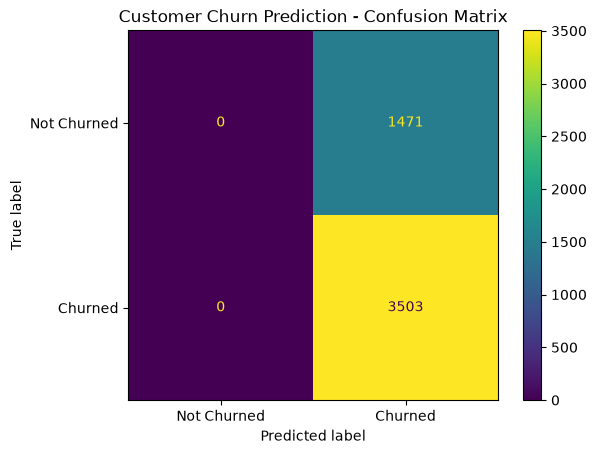

In [175]:
"""
Why are we doing this?

The confusion matrix shows the exact number
of correct and incorrect predictions.

True Negative:
Correctly predicted Not Churned.

False Positive:
Predicted Churn but customer did not churn.

False Negative:
Customer actually churned but model missed them.

True Positive:
Correctly predicted Churn.
"""

churn_cm = confusion_matrix(
    y_churn_test,
    y_churn_pred
)

print(
    churn_cm
)

ConfusionMatrixDisplay(
    confusion_matrix=churn_cm,
    display_labels=[
        "Not Churned",
        "Churned"
    ]
).plot()

plt.title(
    "Customer Churn Prediction - Confusion Matrix"
)

plt.show()

# Think:
# Pay special attention to False Negatives.
#
# False Negative means:
# The customer actually churned,
# but the model failed to identify them.

In [176]:
"""
Why are we doing this?

We create one table containing all important
churn model performance metrics.

This table can later be exported for documentation
and Power BI.
"""

churn_model_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Score": [
        churn_accuracy,
        churn_precision,
        churn_recall,
        churn_f1,
        churn_roc_auc
    ]
})

churn_model_results

# Think:
# Review all metrics together.
#
# Accuracy should ideally be 80%+.
# F1 and ROC-AUC should also be meaningful.

,Metric,Score
0,Accuracy,0.704262
1,Precision,0.704262
2,Recall,1.000000
3,F1 Score,0.826472
4,ROC-AUC,0.497264


In [177]:
"""
Why are we doing this?

Feature importance shows which variables were most useful
for predicting customer churn.

This helps us understand what patterns the model learned.
"""

churn_feature_names = (
    churn_preprocessor
    .get_feature_names_out()
)

churn_feature_importance = pd.DataFrame({
    "Feature": churn_feature_names,

    "Importance": (
        churn_xgb_model
        .feature_importances_
    )
}).sort_values(
    by="Importance",
    ascending=False
)

print(
    churn_feature_importance.head(20)
)

# Think:
# Check which features are most important.
#
# Pay attention to:
# Recency
# Recent order activity
# Total orders
# Customer tenure
# Revenue
# Cancellation behavior
#
# Important does not mean the feature causes churn.
# It means the model used the feature strongly.

                                                 Feature  Importance
25508      categorical__customer_state_Western Australia    0.010269
25507                  categorical__customer_state_Wales    0.009954
25495                   categorical__customer_state_Ohio    0.009914
25491               categorical__customer_state_New York    0.009881
25494       categorical__customer_state_Northern Ireland    0.009721
25500               categorical__customer_state_Scotland    0.009539
25477             categorical__customer_state_California    0.008960
25503             categorical__customer_state_Tamil Nadu    0.008920
14358                  categorical__customer_segment_VIP    0.008614
25504                  categorical__customer_state_Texas    0.008590
11889  categorical__campaign_orders_No_CampaignNo_Cam...    0.008382
25484               categorical__customer_state_Illinois    0.008318
25497           categorical__customer_state_Pennsylvania    0.008178
3      categorical__coupon_orders_

In [178]:
"""
Why are we doing this?

We create a customer-level prediction dataset.

It contains:

- Customer features
- Actual churn
- Predicted churn
- Churn probability
- Prediction status

This dataset can later be connected to Power BI.
"""

churn_results = X_churn_test.copy()

churn_results["Actual_Churned"] = (
    y_churn_test.values
)

churn_results["Predicted_Churned"] = (
    y_churn_pred
)

churn_results["Churn_Probability"] = (
    y_churn_probability
)

churn_results["Prediction_Status"] = (
    churn_results["Actual_Churned"]
    ==
    churn_results["Predicted_Churned"]
).map({
    True: "Correct",
    False: "Wrong"
})

print(
    churn_results.head()
)

# Think:
# Check:
# Actual_Churned
# Predicted_Churned
# Churn_Probability
#
# Churn_Probability should be between 0 and 1.

       total_orders  total_revenue  total_profit  total_quantity  \
15921             9       11601.02       1464.79              66   
15660             6        5492.91       2685.98              30   
11350             7       14214.79       5803.58              44   
8893              5        6463.42       3052.70              32   
9716              3        2081.60        764.24              12   

       average_order_value  average_rating  returned_orders  cancelled_orders  \
15921          1289.002222        3.672670                2                 0   
15660           915.485000        3.859005                1                 1   
11350          2030.684286        3.493433                0                 0   
8893           1292.684000        3.750806                1                 1   
9716            693.866667        4.600000                0                 0   

                                           coupon_orders  \
15921  No_CouponNo_CouponNo_CouponNo_CouponN

In [179]:
"""
Why are we doing this?

We identify customers where the model prediction
does not match the actual churn outcome.

These customers are useful for error analysis.
"""

wrong_churn_predictions = (
    churn_results[
        churn_results["Actual_Churned"]
        !=
        churn_results["Predicted_Churned"]
    ]
)

print(
    "Wrong Churn Predictions:",
    len(wrong_churn_predictions)
)

# Think:
# Investigate why these customers were difficult
# for the model to classify.

Wrong Churn Predictions: 1471


In [180]:
"""
Why are we doing this?

We identify customers whose predicted churn
probability is at least 70%.

These customers are classified as high churn risk
for business analysis.

Important:

A 70% probability does not guarantee that the customer
will churn.

It means the model estimates a high probability
based on the available information.
"""

high_churn_risk = churn_results[
    churn_results["Churn_Probability"] >= 0.70
].copy()

print(
    "High Churn Risk Customers:",
    len(high_churn_risk)
)

# Think:
# Check how many customers are classified as high risk.
#
# Ask:
# 1. How many actually churned?
# 2. What is their recency?
# 3. What is their recent order activity?
# 4. Which customer segments appear frequently?

High Churn Risk Customers: 2861


In [181]:
"""
Why are we doing this?

We check how many high-risk customers actually churned.

This helps us understand whether the high-risk
classification is useful for business analysis.
"""

if len(high_churn_risk) > 0:

    high_risk_actual_churn_rate = (
        high_churn_risk["Actual_Churned"]
        .mean()
        * 100
    )

    print(
        "Actual Churn Rate Among High-Risk Customers:",
        high_risk_actual_churn_rate,
        "%"
    )

else:

    print(
        "No customers have Churn Probability >= 70%."
    )

# Think:
# A high actual churn rate among high-risk customers
# indicates that the risk group is useful.

Actual Churn Rate Among High-Risk Customers: 70.32506116742397 %


In [182]:
"""
Why are we doing this?

We save all important Customer Churn Prediction
outputs into separate CSV files.

These files can later be used for:

- Power BI
- Customer analysis
- Error analysis
- Feature importance analysis
- Model performance reporting
- High-risk customer analysis
- Project documentation
"""

# save customer-level prediction results
churn_results.to_csv(
    "../Data/OG Clean_Data/customer_churn_prediction_results.csv",
    index=False
)

# save feature importance
churn_feature_importance.to_csv(
    "../Data/OG Clean_Data/customer_churn_feature_importance.csv",
    index=False
)

# save model performance
churn_model_results.to_csv(
    "../Data/OG Clean_Data/customer_churn_model_performance.csv",
    index=False
)

# save high-risk customers
high_churn_risk.to_csv(
    "../Data/OG Clean_Data/high_churn_risk_customers.csv",
    index=False
)

# save threshold results
threshold_results.to_csv(
    "../Data/OG Clean_Data/customer_churn_threshold_results.csv",
    index=False
)

print(
    "Customer Churn Prediction files saved successfully."
)

print()

print(
    "1. customer_churn_prediction_results.csv"
)

print(
    "2. customer_churn_feature_importance.csv"
)

print(
    "3. customer_churn_model_performance.csv"
)

print(
    "4. high_churn_risk_customers.csv"
)

print(
    "5. customer_churn_threshold_results.csv"
)

# Think:
# All five CSV files should now be available inside:
#
# ../Data/OG Clean_Data/
#
# The most important files for Power BI are:
#
# customer_churn_prediction_results.csv
# high_churn_risk_customers.csv
# customer_churn_model_performance.csv

Customer Churn Prediction files saved successfully.

1. customer_churn_prediction_results.csv
2. customer_churn_feature_importance.csv
3. customer_churn_model_performance.csv
4. high_churn_risk_customers.csv
5. customer_churn_threshold_results.csv


In [183]:
# saving cleaned customer data

customer_df.to_csv(
    "../Data/OG Clean_Data/cleaned_customer.csv",
    index=False
)

In [184]:
# saving cleaned order items data

order_items_df.to_csv(
    "../Data/OG Clean_Data/cleaned_order_items.csv",
    index=False
)

In [185]:
# saving cleaned product data

product_df.to_csv(
    "../Data/OG Clean_Data/cleaned_product.csv",
    index=False
)

In [186]:
# saving cleaned dataset statistics

statistics_df.to_csv(
    "../Data/OG Clean_Data/cleaned_dataset_statistics.csv",
    index=False
)

In [187]:
# saving cleaned sales data

sales_df.to_csv(
    "../Data/OG Clean_Data/cleaned_sales.csv",
    index=False
)